In [ ]:
import os

for root, dirs, files in os.walk("/"):
    if "customer_shopping_behavior.csv" in files:
        print(os.path.join(root, "customer_shopping_behavior.csv"))
        break

/customer_shopping_behavior.csv


In [18]:
import pandas as pd

df = pd.read_csv("/content/customer_shopping_behavior.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (3900, 18)


,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,Yes,31,PayPal,Annually


In [ ]:
# Check the dataset dimensions
print("Dataset Shape:", df.shape)

# Check column names and data types
print("\nDataset Information:")
df.info()

Dataset Shape: (3900, 18)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Customer ID             3900 non-null   int64  
 1   Age                     3900 non-null   int64  
 2   Gender                  3900 non-null   object 
 3   Item Purchased          3900 non-null   object 
 4   Category                3900 non-null   object 
 5   Purchase Amount (USD)   3900 non-null   int64  
 6   Location                3900 non-null   object 
 7   Size                    3900 non-null   object 
 8   Color                   3900 non-null   object 
 9   Season                  3900 non-null   object 
 10  Review Rating           3863 non-null   float64
 11  Subscription Status     3900 non-null   object 
 12  Shipping Type           3900 non-null   object 
 13  Discount Applied        3900 non-null   objec

In [ ]:
# Step 5: Data Quality Check

# Check missing values in each column
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:")
print(df.duplicated().sum())

# Check basic statistics
print("\nSummary Statistics:")
display(df.describe())

Missing Values:
Customer ID                0
Age                        0
Gender                     0
Item Purchased             0
Category                   0
Purchase Amount (USD)      0
Location                   0
Size                       0
Color                      0
Season                     0
Review Rating             37
Subscription Status        0
Shipping Type              0
Discount Applied           0
Promo Code Used            0
Previous Purchases         0
Payment Method             0
Frequency of Purchases     0
dtype: int64

Duplicate Rows:
0

Summary Statistics:


,Customer ID,Age,Purchase Amount (USD),Review Rating,Previous Purchases
count,3900.000000,3900.000000,3900.000000,3863.000000,3900.000000
mean,1950.500000,44.068462,59.764359,3.750065,25.351538
std,1125.977353,15.207589,23.685392,0.716983,14.447125
min,1.000000,18.000000,20.000000,2.500000,1.000000
25%,975.750000,31.000000,39.000000,3.100000,13.000000
50%,1950.500000,44.000000,60.000000,3.800000,25.000000
75%,2925.250000,57.000000,81.000000,4.400000,38.000000
max,3900.000000,70.000000,100.000000,5.000000,50.000000


In [ ]:
# Step 6: Handle Missing Values

# Create a copy of the original dataset
df_clean = df.copy()

# Calculate the median review rating
median_rating = df_clean["Review Rating"].median()

print("Median Review Rating:", median_rating)

# Mark which ratings were originally missing
df_clean["Rating Was Missing"] = df_clean["Review Rating"].isna()

# Fill missing ratings with the median
df_clean["Review Rating"] = df_clean["Review Rating"].fillna(median_rating)

# Check remaining missing values
print("\nRemaining Missing Values:")
print(df_clean.isnull().sum().sum())

Median Review Rating: 3.8

Remaining Missing Values:
0


In [ ]:
# Step 7: Sales Revenue by Product Category

category_sales = (
    df_clean.groupby("Category")["Purchase Amount (USD)"]
    .sum()
    .sort_values(ascending=False)
)

print("Total Sales Revenue by Category:")
display(category_sales)

Total Sales Revenue by Category:


,Purchase Amount (USD)
Category,
Clothing,104264
Accessories,74200
Footwear,36093
Outerwear,18524


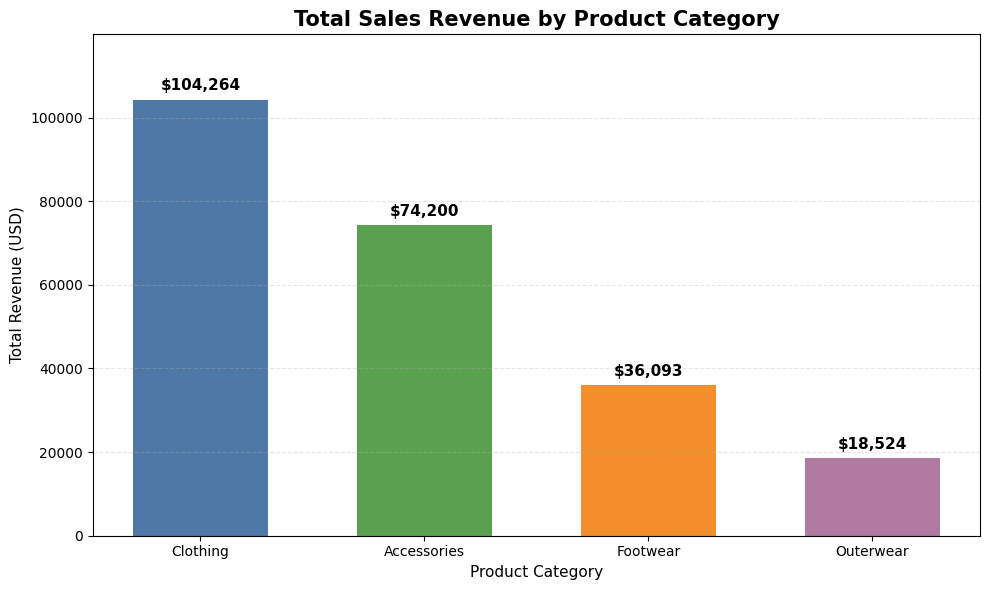

In [ ]:
# Step 8: Visualize Sales Revenue by Category

import matplotlib.pyplot as plt

# Define colors for each category
colors = ["#4E79A7", "#59A14F", "#F28E2B", "#B07AA1"]

plt.figure(figsize=(10, 6))

bars = plt.bar(
    category_sales.index,
    category_sales.values,
    color=colors,
    width=0.6
)

# Add exact revenue values above each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1500,
        f"${height:,.0f}",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

# Chart title and labels
plt.title(
    "Total Sales Revenue by Product Category",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Product Category", fontsize=11)
plt.ylabel("Total Revenue (USD)", fontsize=11)

plt.ylim(0, category_sales.max() * 1.15)
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()

# Save high-quality chart for GitHub Portfolio
plt.savefig(
    "sales_revenue_by_category.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# Step 9: Detailed Sales Performance Analysis

category_performance = (
    df_clean.groupby("Category")
    .agg(
        Total_Revenue=("Purchase Amount (USD)", "sum"),
        Purchase_Count=("Customer ID", "count"),
        Average_Purchase=("Purchase Amount (USD)", "mean")
    )
    .sort_values("Total_Revenue", ascending=False)
)

# Calculate revenue contribution percentage
total_revenue = category_performance["Total_Revenue"].sum()

category_performance["Revenue_Share_Pct"] = (
    category_performance["Total_Revenue"] / total_revenue * 100
)

# Format results
display(category_performance.round(2))

,Total_Revenue,Purchase_Count,Average_Purchase,Revenue_Share_Pct
Category,,,,
Clothing,104264,1737,60.03,44.73
Accessories,74200,1240,59.84,31.83
Footwear,36093,599,60.26,15.49
Outerwear,18524,324,57.17,7.95


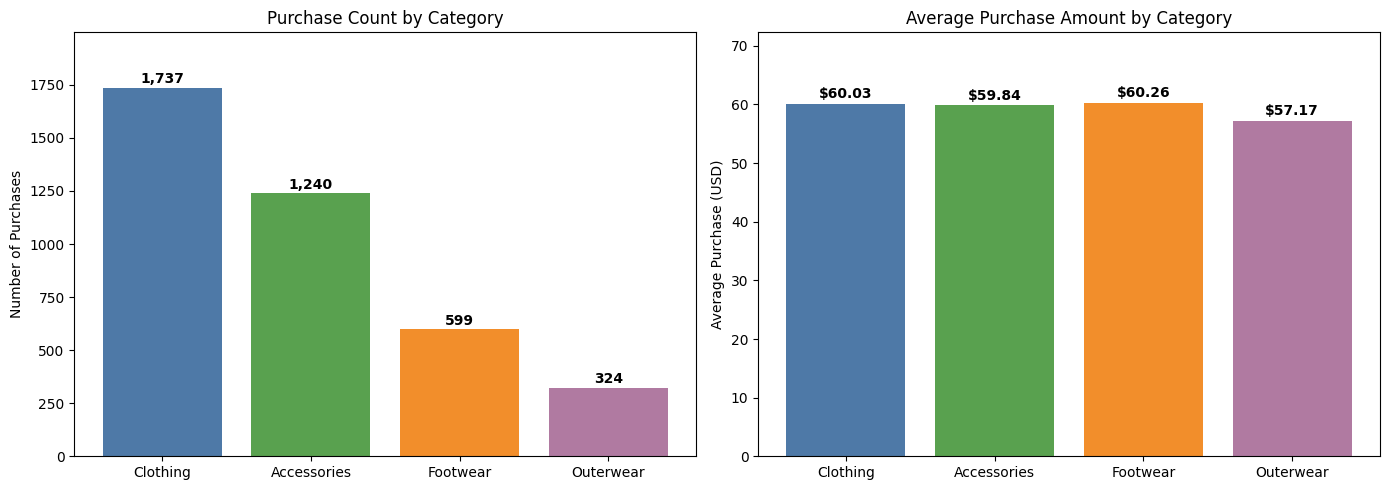

In [ ]:
# Step 10: Sales Volume vs Average Purchase Amount

import matplotlib.pyplot as plt

categories = category_performance.index
counts = category_performance["Purchase_Count"]
averages = category_performance["Average_Purchase"]

colors = ["#4E79A7", "#59A14F", "#F28E2B", "#B07AA1"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Chart 1: Purchase Count
bars1 = axes[0].bar(categories, counts, color=colors)

axes[0].set_title("Purchase Count by Category")
axes[0].set_ylabel("Number of Purchases")
axes[0].set_ylim(0, counts.max() * 1.15)

for bar in bars1:
    axes[0].text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 20,
        f"{bar.get_height():,.0f}",
        ha="center",
        fontweight="bold"
    )

# Chart 2: Average Purchase Amount
bars2 = axes[1].bar(categories, averages, color=colors)

axes[1].set_title("Average Purchase Amount by Category")
axes[1].set_ylabel("Average Purchase (USD)")
axes[1].set_ylim(0, averages.max() * 1.2)

for bar in bars2:
    axes[1].text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 1,
        f"${bar.get_height():.2f}",
        ha="center",
        fontweight="bold"
    )

plt.tight_layout()

plt.savefig(
    "sales_volume_vs_average_purchase.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# Step 11: Customer Segmentation by Age Group

import pandas as pd

# Create age groups
age_bins = [0, 25, 35, 45, 55, 100]
age_labels = ["18-25", "26-35", "36-45", "46-55", "56+"]

df_clean["Age Group"] = pd.cut(
    df_clean["Age"],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True
)

# Analyze purchasing behavior by age group
age_analysis = (
    df_clean.groupby("Age Group", observed=True)
    .agg(
        Customer_Count=("Customer ID", "nunique"),
        Total_Revenue=("Purchase Amount (USD)", "sum"),
        Average_Purchase=("Purchase Amount (USD)", "mean")
    )
)

display(age_analysis.round(2))

,Customer_Count,Total_Revenue,Average_Purchase
Age Group,,,
18-25,571,34630,60.65
26-35,742,44342,59.76
36-45,729,43234,59.31
46-55,753,45619,60.58
56+,1105,65256,59.06


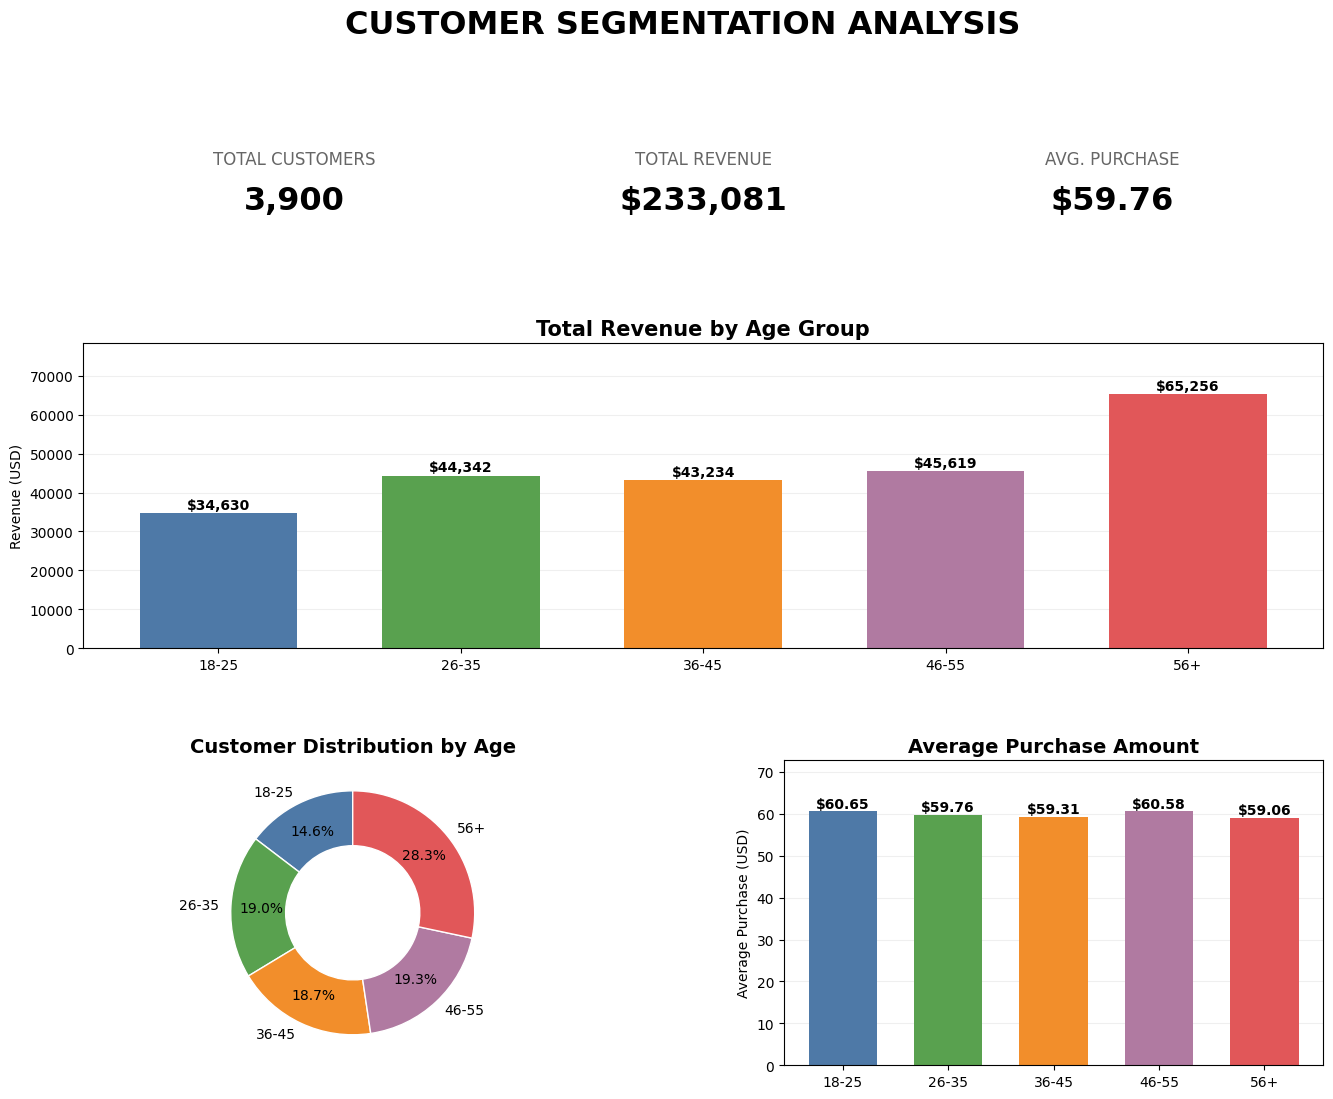

In [ ]:

# Step 12: Customer Segmentation Dashboard

import matplotlib.pyplot as plt
import numpy as np

# Prepare data
ages = age_analysis.index.astype(str)
customers = age_analysis["Customer_Count"]
revenue = age_analysis["Total_Revenue"]
average = age_analysis["Average_Purchase"]

colors = ["#4E79A7", "#59A14F", "#F28E2B",
          "#B07AA1", "#E15759"]

total_customers = customers.sum()
total_revenue = revenue.sum()
overall_average = total_revenue / total_customers

# Create dashboard
fig = plt.figure(figsize=(16, 12), facecolor="white")

gs = fig.add_gridspec(
    3, 2,
    height_ratios=[0.65, 2.2, 2.2],
    hspace=0.48,
    wspace=0.3
)

# Dashboard title
fig.suptitle(
    "CUSTOMER SEGMENTATION ANALYSIS",
    fontsize=23,
    fontweight="bold",
    y=0.99
)

# KPI Summary
ax_kpi = fig.add_subplot(gs[0, :])
ax_kpi.axis("off")

kpis = [
    ("TOTAL CUSTOMERS", f"{total_customers:,}"),
    ("TOTAL REVENUE", f"${total_revenue:,.0f}"),
    ("AVG. PURCHASE", f"${overall_average:.2f}")
]

for x, (label, value) in zip([0.17, 0.5, 0.83], kpis):
    ax_kpi.text(x, 0.75, label, ha="center",
                fontsize=12, color="#666666",
                transform=ax_kpi.transAxes)
    ax_kpi.text(x, 0.25, value, ha="center",
                fontsize=23, fontweight="bold",
                transform=ax_kpi.transAxes)

# Chart 1: Revenue
ax1 = fig.add_subplot(gs[1, :])
bars = ax1.bar(ages, revenue, color=colors, width=0.65)

ax1.set_title("Total Revenue by Age Group",
              fontsize=15, fontweight="bold")
ax1.set_ylabel("Revenue (USD)")
ax1.set_ylim(0, revenue.max() * 1.2)
ax1.grid(axis="y", alpha=0.2)
ax1.set_axisbelow(True)

for bar in bars:
    h = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2,
             h + 1000, f"${h:,.0f}",
             ha="center", fontweight="bold")

# Chart 2: Customer Distribution
ax2 = fig.add_subplot(gs[2, 0])

wedges, texts, autotexts = ax2.pie(
    customers,
    labels=ages,
    autopct="%1.1f%%",
    startangle=90,
    colors=colors,
    pctdistance=0.75,
    wedgeprops={"width": 0.45, "edgecolor": "white"}
)

ax2.set_title("Customer Distribution by Age",
              fontsize=14, fontweight="bold")

# Chart 3: Average Purchase
ax3 = fig.add_subplot(gs[2, 1])

bars = ax3.bar(ages, average, color=colors, width=0.65)

ax3.set_title("Average Purchase Amount",
              fontsize=14, fontweight="bold")
ax3.set_ylabel("Average Purchase (USD)")
ax3.set_ylim(0, average.max() * 1.2)
ax3.grid(axis="y", alpha=0.2)
ax3.set_axisbelow(True)

for bar in bars:
    h = bar.get_height()
    ax3.text(bar.get_x() + bar.get_width()/2,
             h + 0.8, f"${h:.2f}",
             ha="center", fontweight="bold")

# Save dashboard
plt.savefig(
    "customer_segmentation_dashboard.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


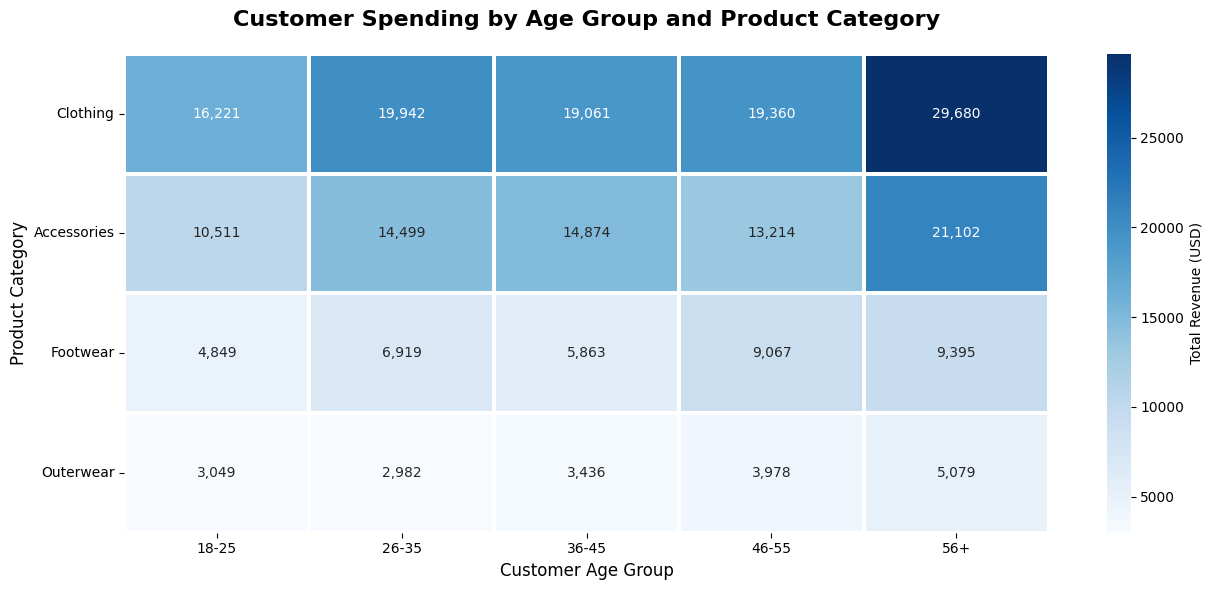

In [ ]:

# Step 13: Revenue Heatmap by Age Group and Product Category

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Create a pivot table
age_category_revenue = pd.pivot_table(
    df_clean,
    values="Purchase Amount (USD)",
    index="Category",
    columns="Age Group",
    aggfunc="sum",
    fill_value=0,
    observed=True
)

# Order product categories by total revenue
age_category_revenue = age_category_revenue.loc[
    age_category_revenue.sum(axis=1).sort_values(
        ascending=False
    ).index
]

# Create heatmap
plt.figure(figsize=(13, 6))

sns.heatmap(
    age_category_revenue,
    annot=True,
    fmt=",.0f",
    cmap="Blues",
    linewidths=1.5,
    linecolor="white",
    cbar_kws={"label": "Total Revenue (USD)"}
)

plt.title(
    "Customer Spending by Age Group and Product Category",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.xlabel("Customer Age Group", fontsize=12)
plt.ylabel("Product Category", fontsize=12)

plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.tight_layout()

plt.savefig(
    "age_category_revenue_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Category Purchase Distribution (%):


Category,Clothing,Accessories,Footwear,Outerwear
Age Group,,,,
18-25,47.11,30.12,13.84,8.93
26-35,45.42,32.75,14.56,7.28
36-45,43.76,34.16,13.99,8.09
46-55,42.63,28.82,19.92,8.63
56+,44.43,32.49,14.48,8.60


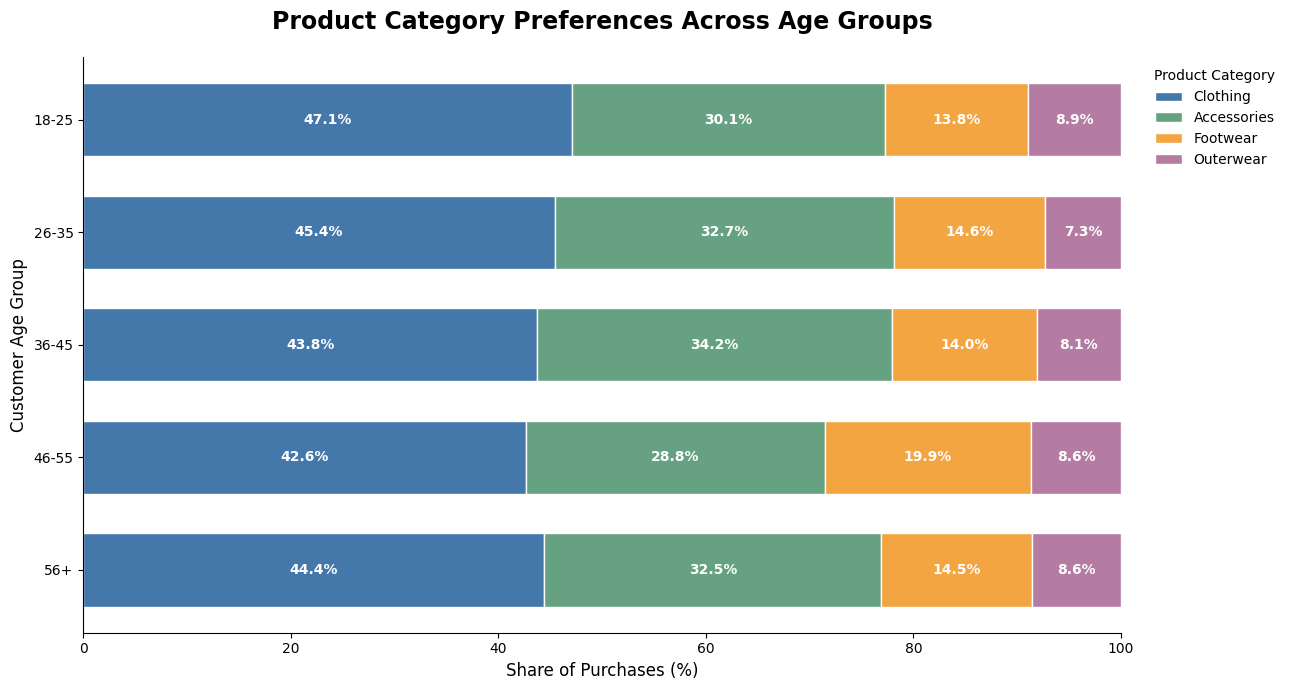

In [ ]:

# Step 14: Product Category Preferences by Age Group

import pandas as pd
import matplotlib.pyplot as plt

# Count purchases by age group and category
category_counts = pd.crosstab(
    df_clean["Age Group"],
    df_clean["Category"]
)

# Calculate percentages within each age group
category_percent = (
    category_counts.div(
        category_counts.sum(axis=1),
        axis=0
    ) * 100
)

# Set category order
category_order = [
    "Clothing", "Accessories",
    "Footwear", "Outerwear"
]

category_percent = category_percent[category_order]

print("Category Purchase Distribution (%):")
display(category_percent.round(2))

# Professional chart colors
colors = [
    "#4477AA",
    "#66A182",
    "#F2A541",
    "#B47BA3"
]

fig, ax = plt.subplots(figsize=(13, 7))

left = [0] * len(category_percent)

# Create horizontal stacked bar chart
for i, category in enumerate(category_order):

    values = category_percent[category]

    bars = ax.barh(
        category_percent.index.astype(str),
        values,
        left=left,
        color=colors[i],
        label=category,
        height=0.65,
        edgecolor="white"
    )

    # Add percentage labels
    for j, value in enumerate(values):
        if value >= 7:
            ax.text(
                left[j] + value / 2,
                j,
                f"{value:.1f}%",
                ha="center",
                va="center",
                color="white",
                fontsize=10,
                fontweight="bold"
            )

    left = [
        left[j] + values.iloc[j]
        for j in range(len(values))
    ]

ax.set_title(
    "Product Category Preferences Across Age Groups",
    fontsize=17,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Share of Purchases (%)", fontsize=12)
ax.set_ylabel("Customer Age Group", fontsize=12)

ax.set_xlim(0, 100)
ax.invert_yaxis()

ax.legend(
    title="Product Category",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    "age_group_category_preferences.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:

# Step 15: Chi-Square Test of Independence

import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency

# Contingency table: actual purchase counts
contingency_table = pd.crosstab(
    df_clean["Age Group"],
    df_clean["Category"]
)

print("Observed Purchase Counts:")
display(contingency_table)

# Perform Chi-Square Test
chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

# Display statistical results
print("\nCHI-SQUARE TEST RESULTS")
print("-" * 40)
print(f"Chi-Square Statistic: {chi2:.4f}")
print(f"Degrees of Freedom: {dof}")
print(f"P-value: {p_value:.6f}")
print(f"Significance Level: 0.05")

# Check assumptions
print(f"\nMinimum Expected Count: {expected.min():.2f}")
print(f"Expected Counts Below 5: {(expected < 5).sum()}")

# Calculate Cramer's V
n = contingency_table.to_numpy().sum()
r, c = contingency_table.shape

cramers_v = np.sqrt(
    chi2 / (n * min(r - 1, c - 1))
)

print(f"Cramer's V: {cramers_v:.4f}")

# Interpret result
print("\nSTATISTICAL INTERPRETATION")

if p_value < 0.05:
    print("Reject the null hypothesis.")
    print(
        "There is a statistically significant association "
        "between age group and product category."
    )
else:
    print("Fail to reject the null hypothesis.")
    print(
        "There is insufficient evidence of an association "
        "between age group and product category."
    )


Observed Purchase Counts:


Category,Accessories,Clothing,Footwear,Outerwear
Age Group,,,,
18-25,172,269,79,51
26-35,243,337,108,54
36-45,249,319,102,59
46-55,217,321,150,65
56+,359,491,160,95



CHI-SQUARE TEST RESULTS
----------------------------------------
Chi-Square Statistic: 20.2362
Degrees of Freedom: 12
P-value: 0.062748
Significance Level: 0.05

Minimum Expected Count: 47.44
Expected Counts Below 5: 0
Cramer's V: 0.0416

STATISTICAL INTERPRETATION
Fail to reject the null hypothesis.
There is insufficient evidence of an association between age group and product category.



### Statistical Findings: Age Group and Product Category

A Chi-Square Test of Independence was conducted to examine the relationship between customer age groups and product categories.

**Test Results**
- Chi-Square Statistic: 20.2362
- Degrees of Freedom: 12
- P-value: 0.062748
- Cramer's V: 0.0416
- Significance Level: 0.05

**Key Finding**

The test did not identify a statistically significant association between age group and product category at the 5% significance level.

Although customers aged 46–55 showed a relatively higher proportion of footwear purchases (19.92%), the overall statistical evidence was insufficient to establish an association between age and product category.

**Business Implication**

Age-based product targeting should not be prioritized solely on the basis of these observed differences. Additional variables, such as purchase frequency, subscription status, and promotional behavior, should be investigated to identify potentially more informative customer segments.

**Limitation**

The analysis assumes independent purchase observations and does not establish causal relationships.


In [ ]:
import pandas as pd

df = pd.read_csv("/customer_shopping_behavior.csv")

df_clean = df.copy()

# Fill missing review ratings with the median
median_rating = df_clean["Review Rating"].median()
df_clean["Review Rating"] = df_clean["Review Rating"].fillna(median_rating)

print("Dataset loaded successfully!")
print("Dataset Shape:", df_clean.shape)
print("Remaining Missing Values:", df_clean.isnull().sum().sum())

Dataset loaded successfully!
Dataset Shape: (3900, 18)
Remaining Missing Values: 0


In [ ]:

# STEP 16: Subscription Status Analysis

import pandas as pd

# Analyze subscription status
subscription_analysis = (
    df_clean.groupby("Subscription Status")
    .agg(
        Customer_Count=("Customer ID", "count"),
        Total_Revenue=("Purchase Amount (USD)", "sum"),
        Average_Purchase=("Purchase Amount (USD)", "mean"),
        Median_Purchase=("Purchase Amount (USD)", "median")
    )
)

# Calculate customer percentage
subscription_analysis["Customer_Share (%)"] = (
    subscription_analysis["Customer_Count"]
    / subscription_analysis["Customer_Count"].sum() * 100
)

# Calculate revenue percentage
subscription_analysis["Revenue_Share (%)"] = (
    subscription_analysis["Total_Revenue"]
    / subscription_analysis["Total_Revenue"].sum() * 100
)

print("SUBSCRIPTION STATUS ANALYSIS")
display(subscription_analysis.round(2))


SUBSCRIPTION STATUS ANALYSIS


,Customer_Count,Total_Revenue,Average_Purchase,Median_Purchase,Customer_Share (%),Revenue_Share (%)
Subscription Status,,,,,,
No,2847,170436,59.87,60.0,73.0,73.12
Yes,1053,62645,59.49,60.0,27.0,26.88


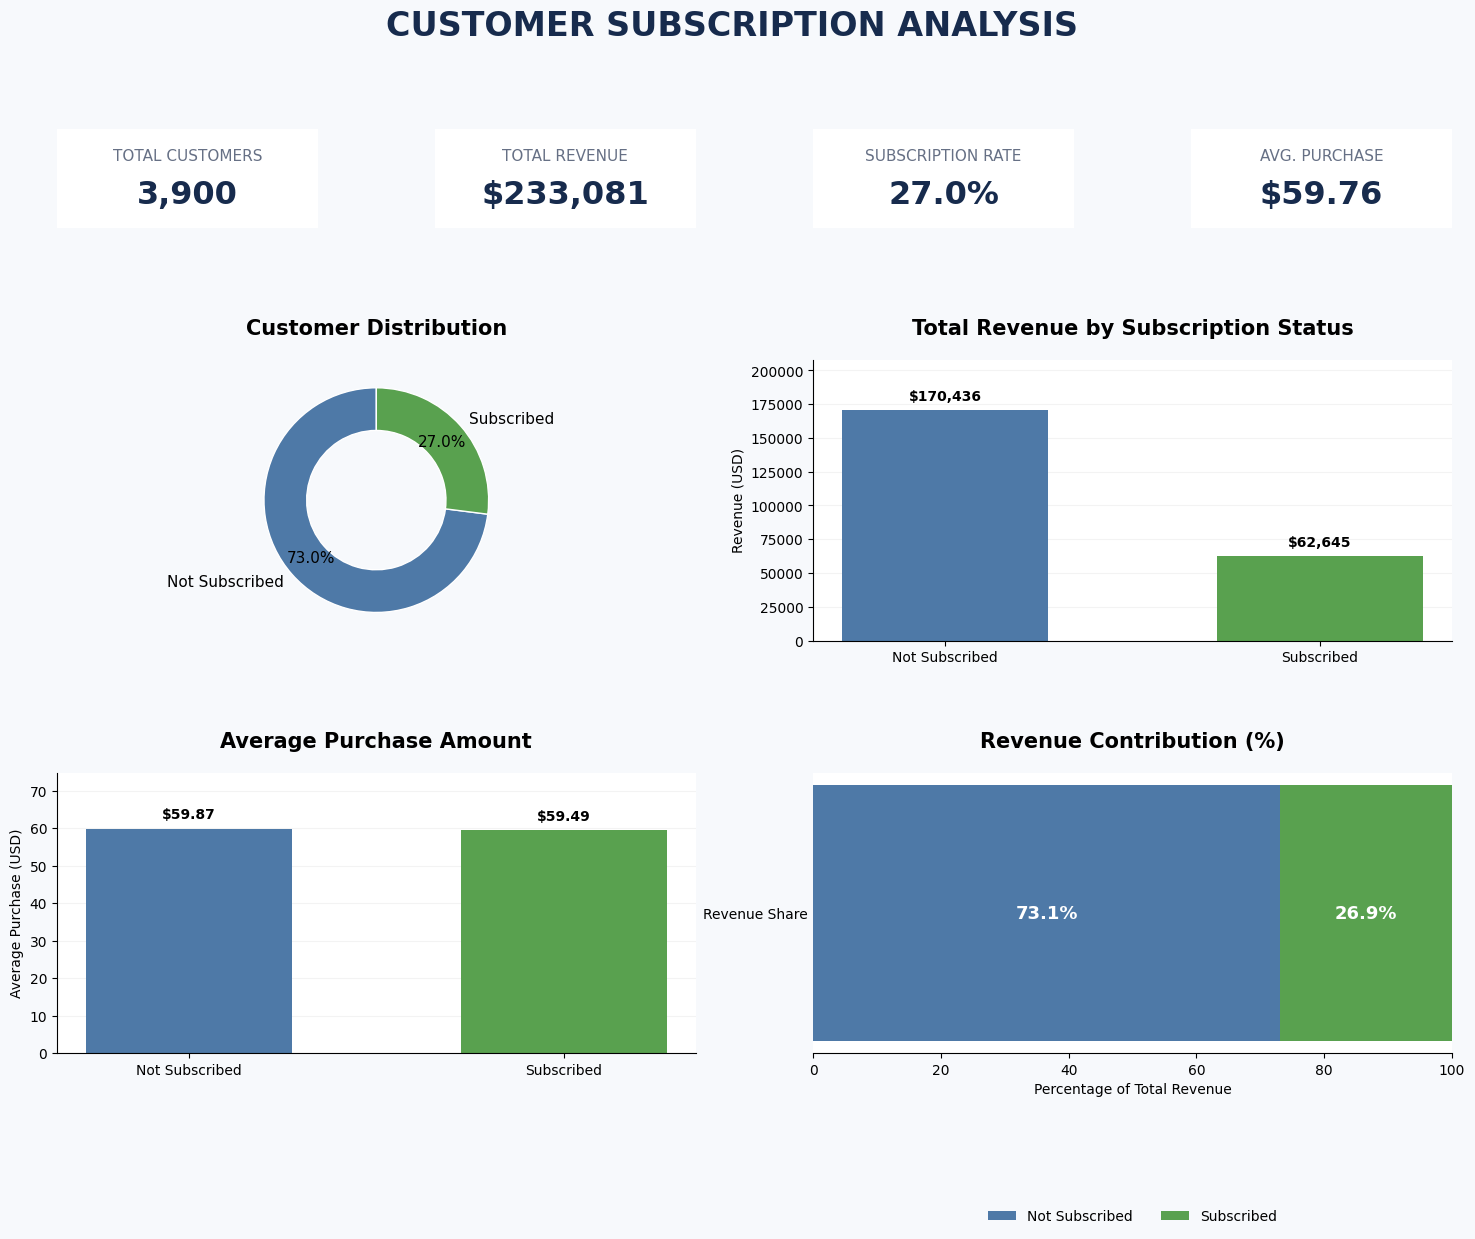

In [ ]:

# STEP 16.2: Subscription Status Dashboard

import matplotlib.pyplot as plt
import numpy as np

# Prepare data
sub = subscription_analysis.reindex(["No", "Yes"])

labels = ["Not Subscribed", "Subscribed"]
colors = ["#4E79A7", "#59A14F"]

customers = sub["Customer_Count"].values
revenue = sub["Total_Revenue"].values
average = sub["Average_Purchase"].values

total_customers = customers.sum()
total_revenue = revenue.sum()
subscription_rate = customers[1] / total_customers * 100
overall_average = total_revenue / total_customers

# Dashboard setup
fig = plt.figure(figsize=(18, 12), facecolor="#F7F9FC")

gs = fig.add_gridspec(
    3, 4,
    height_ratios=[0.7, 2, 2],
    hspace=0.6,
    wspace=0.45
)

fig.suptitle(
    "CUSTOMER SUBSCRIPTION ANALYSIS",
    fontsize=24,
    fontweight="bold",
    y=0.98,
    color="#172B4D"
)

# KPI Cards
kpis = [
    ("TOTAL CUSTOMERS", f"{total_customers:,}"),
    ("TOTAL REVENUE", f"${total_revenue:,.0f}"),
    ("SUBSCRIPTION RATE", f"{subscription_rate:.1f}%"),
    ("AVG. PURCHASE", f"${overall_average:.2f}")
]

for i, (name, value) in enumerate(kpis):
    ax = fig.add_subplot(gs[0, i])
    ax.set_facecolor("white")

    for spine in ax.spines.values():
        spine.set_visible(False)

    ax.set_xticks([])
    ax.set_yticks([])

    ax.text(
        0.5, 0.68, name,
        ha="center", fontsize=11,
        color="#667085", transform=ax.transAxes
    )

    ax.text(
        0.5, 0.25, value,
        ha="center", fontsize=23,
        fontweight="bold",
        color="#172B4D", transform=ax.transAxes
    )

# Chart 1: Customer Distribution
ax1 = fig.add_subplot(gs[1, :2])

ax1.pie(
    customers,
    labels=labels,
    autopct="%1.1f%%",
    startangle=90,
    colors=colors,
    pctdistance=0.78,
    wedgeprops=dict(width=0.38, edgecolor="white"),
    textprops={"fontsize": 11}
)

ax1.set_title(
    "Customer Distribution",
    fontsize=15, fontweight="bold", pad=18
)

# Chart 2: Total Revenue
ax2 = fig.add_subplot(gs[1, 2:])

bars = ax2.bar(
    labels, revenue,
    color=colors, width=0.55
)

ax2.set_title(
    "Total Revenue by Subscription Status",
    fontsize=15, fontweight="bold", pad=18
)

ax2.set_ylabel("Revenue (USD)")
ax2.set_ylim(0, max(revenue) * 1.22)

ax2.bar_label(
    bars,
    labels=[f"${v:,.0f}" for v in revenue],
    padding=5, fontweight="bold"
)

ax2.spines[["top", "right"]].set_visible(False)
ax2.grid(axis="y", alpha=0.15)
ax2.set_axisbelow(True)

# Chart 3: Average Purchase
ax3 = fig.add_subplot(gs[2, :2])

bars = ax3.bar(
    labels, average,
    color=colors, width=0.55
)

ax3.set_title(
    "Average Purchase Amount",
    fontsize=15, fontweight="bold", pad=18
)

ax3.set_ylabel("Average Purchase (USD)")
ax3.set_ylim(0, max(average) * 1.25)

ax3.bar_label(
    bars,
    labels=[f"${v:.2f}" for v in average],
    padding=5, fontweight="bold"
)

ax3.spines[["top", "right"]].set_visible(False)
ax3.grid(axis="y", alpha=0.15)
ax3.set_axisbelow(True)

# Chart 4: Revenue Contribution
ax4 = fig.add_subplot(gs[2, 2:])

shares = revenue / total_revenue * 100
left = 0

for share, color, label in zip(shares, colors, labels):
    ax4.barh(
        ["Revenue Share"], share,
        left=left, color=color,
        height=0.35, label=label
    )

    ax4.text(
        left + share / 2, 0,
        f"{share:.1f}%",
        ha="center", va="center",
        color="white", fontweight="bold",
        fontsize=13
    )

    left += share

ax4.set_xlim(0, 100)

ax4.set_title(
    "Revenue Contribution (%)",
    fontsize=15, fontweight="bold", pad=18
)

ax4.legend(
    loc="lower center",
    bbox_to_anchor=(0.5, -0.65),
    ncol=2, frameon=False
)

ax4.spines[["top", "right", "left"]].set_visible(False)
ax4.tick_params(axis="y", length=0)
ax4.set_xlabel("Percentage of Total Revenue")

# Save dashboard
plt.savefig(
    "subscription_analysis_dashboard.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()


In [ ]:
# STEP 16.3: Statistical Comparison of Subscription Groups

import pandas as pd
import numpy as np
from scipy import stats

# Prepare the two customer groups
subscribed = df_clean.loc[
    df_clean["Subscription Status"] == "Yes",
    "Purchase Amount (USD)"
].dropna()

not_subscribed = df_clean.loc[
    df_clean["Subscription Status"] == "No",
    "Purchase Amount (USD)"
].dropna()

# Perform Welch's independent samples t-test
t_stat, p_value = stats.ttest_ind(
    subscribed,
    not_subscribed,
    equal_var=False
)

# Calculate descriptive statistics
comparison = pd.DataFrame({
    "Group": ["Subscribed", "Not Subscribed"],
    "Sample Size": [len(subscribed), len(not_subscribed)],
    "Mean Purchase ($)": [subscribed.mean(), not_subscribed.mean()],
    "Std. Deviation": [subscribed.std(), not_subscribed.std()],
    "Median Purchase ($)": [subscribed.median(), not_subscribed.median()]
})

print("SUBSCRIPTION GROUP STATISTICAL COMPARISON")
display(comparison.round(2))

print("\nWELCH'S INDEPENDENT SAMPLES T-TEST")
print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {p_value:.6f}")
print("Significance Level: 0.05")

if p_value < 0.05:
    print("\nResult: Statistically significant difference.")
    print("Reject the null hypothesis.")
else:
    print("\nResult: No statistically significant difference detected.")
    print("Fail to reject the null hypothesis.")

SUBSCRIPTION GROUP STATISTICAL COMPARISON


,Group,Sample Size,Mean Purchase ($),Std. Deviation,Median Purchase ($)
0,Subscribed,1053,59.49,23.45,60.0
1,Not Subscribed,2847,59.87,23.78,60.0



WELCH'S INDEPENDENT SAMPLES T-TEST
T-statistic: -0.4396
P-value: 0.660292
Significance Level: 0.05

Result: No statistically significant difference detected.
Fail to reject the null hypothesis.


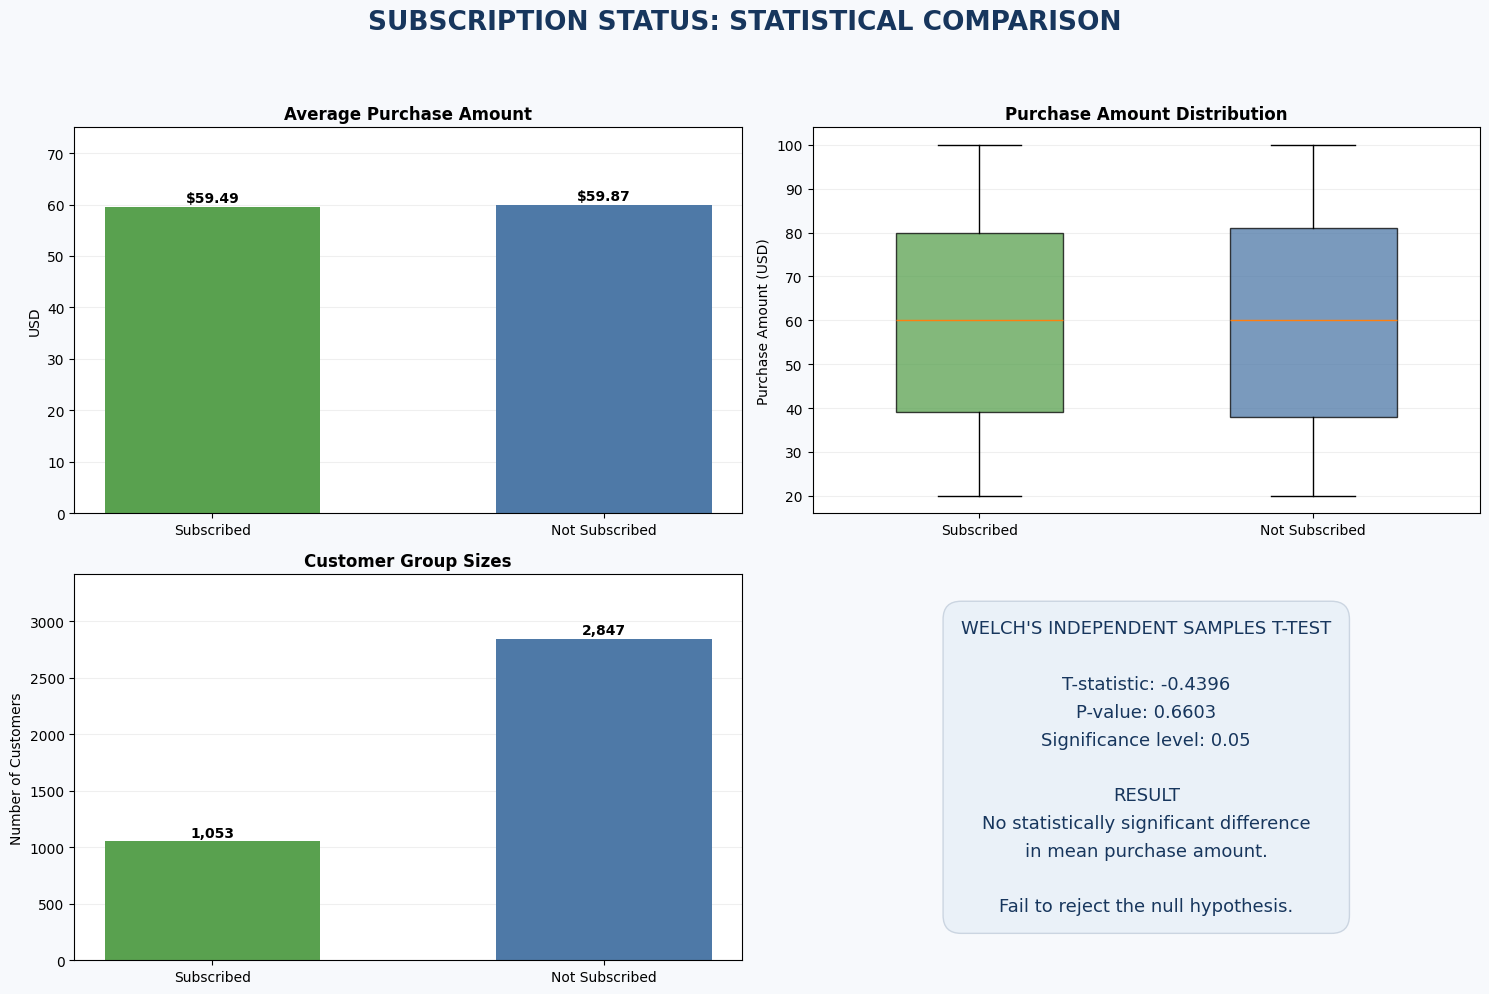

In [ ]:

# STEP 16.3.2: Subscription Statistical Comparison Dashboard

import matplotlib.pyplot as plt
import numpy as np

# Data from Step 16.3.1
groups = ["Subscribed", "Not Subscribed"]
means = [subscribed.mean(), not_subscribed.mean()]
medians = [subscribed.median(), not_subscribed.median()]
counts = [len(subscribed), len(not_subscribed)]
colors = ["#59A14F", "#4E79A7"]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.patch.set_facecolor("#F7F9FC")

fig.suptitle(
    "SUBSCRIPTION STATUS: STATISTICAL COMPARISON",
    fontsize=19, fontweight="bold", color="#17365D", y=0.99
)

# Chart 1: Average purchase
ax = axes[0, 0]
bars = ax.bar(groups, means, color=colors, width=0.55)
ax.set_title("Average Purchase Amount", fontweight="bold")
ax.set_ylabel("USD")
ax.set_ylim(0, 75)

for bar, value in zip(bars, means):
    ax.text(bar.get_x() + bar.get_width()/2,
            value + 1, f"${value:.2f}",
            ha="center", fontweight="bold")

# Chart 2: Purchase distribution
ax = axes[0, 1]
bp = ax.boxplot(
    [subscribed, not_subscribed],
    tick_labels=groups,
    patch_artist=True,
    widths=0.5
)
for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.75)

ax.set_title("Purchase Amount Distribution", fontweight="bold")
ax.set_ylabel("Purchase Amount (USD)")

# Chart 3: Customer count
ax = axes[1, 0]
bars = ax.bar(groups, counts, color=colors, width=0.55)
ax.set_title("Customer Group Sizes", fontweight="bold")
ax.set_ylabel("Number of Customers")
ax.set_ylim(0, max(counts) * 1.2)

for bar, value in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width()/2,
            value + 40, f"{value:,}",
            ha="center", fontweight="bold")

# Chart 4: Statistical test summary
ax = axes[1, 1]
ax.axis("off")

result = (
    "WELCH'S INDEPENDENT SAMPLES T-TEST\n\n"
    f"T-statistic: {t_stat:.4f}\n"
    f"P-value: {p_value:.4f}\n"
    "Significance level: 0.05\n\n"
    "RESULT\n"
    "No statistically significant difference\n"
    "in mean purchase amount.\n\n"
    "Fail to reject the null hypothesis."
)

ax.text(
    0.5, 0.5, result,
    ha="center", va="center",
    fontsize=13, linespacing=1.7,
    color="#17365D",
    bbox=dict(boxstyle="round,pad=1",
              facecolor="#EAF1F8",
              edgecolor="#CBD5E1")
)

for ax in axes.flat:
    if ax.axison:
        ax.grid(axis="y", alpha=0.2)
        ax.set_axisbelow(True)

plt.tight_layout(rect=[0, 0, 1, 0.95])

plt.savefig(
    "subscription_statistical_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Key Findings: Subscription Status and Customer Spending

**Statistical Results**

A Welch's independent samples t-test was conducted to compare average purchase amounts between subscribed and non-subscribed customers.

- Subscribed customers: $59.49 average purchase
- Non-subscribed customers: $59.87 average purchase
- Mean difference: $0.38
- P-value: 0.6603
- Significance level: 0.05

**Business Interpretation**

The results indicate no statistically significant difference in average purchase amounts between subscribed and non-subscribed customers.

Although subscribed customers represent approximately 27% of the dataset, their average purchase amount is nearly identical to that of non-subscribed customers.

**Business Recommendation**

Retailers should not assume that subscription membership automatically leads to higher spending per transaction. Future analysis should examine purchase frequency, customer retention, and customer lifetime value to better understand the potential benefits of subscription programs.

**Limitation**

This analysis is based on observational data and does not establish a causal relationship between subscription status and purchasing behavior.

In [ ]:

# STEP 17.1: Explore Discount and Promotional Variables

# Display all available columns
print("DATASET COLUMNS")
print(df_clean.columns.tolist())

# Identify discount-related columns
keywords = ["discount", "promo", "coupon"]

discount_columns = [
    col for col in df_clean.columns
    if any(word in col.lower() for word in keywords)
]

print("\nDISCOUNT-RELATED COLUMNS")
print(discount_columns)

# Display sample values
if discount_columns:
    display(df_clean[discount_columns].head(10))
else:
    print("No discount-related columns found.")


DATASET COLUMNS
['Customer ID', 'Age', 'Gender', 'Item Purchased', 'Category', 'Purchase Amount (USD)', 'Location', 'Size', 'Color', 'Season', 'Review Rating', 'Subscription Status', 'Shipping Type', 'Discount Applied', 'Promo Code Used', 'Previous Purchases', 'Payment Method', 'Frequency of Purchases']

DISCOUNT-RELATED COLUMNS
['Discount Applied', 'Promo Code Used']


,Discount Applied,Promo Code Used
0,Yes,Yes
1,Yes,Yes
2,Yes,Yes
3,Yes,Yes
4,Yes,Yes
5,Yes,Yes
6,Yes,Yes
7,Yes,Yes
8,Yes,Yes
9,Yes,Yes


In [ ]:

# STEP 17.2: Discount and Promotion Overview

import pandas as pd

# 1. Discount usage
print("=" * 55)
print("DISCOUNT USAGE ANALYSIS")
print("=" * 55)

discount_summary = (
    df_clean.groupby("Discount Applied")
    .agg(
        Customer_Count=("Customer ID", "count"),
        Total_Revenue=("Purchase Amount (USD)", "sum"),
        Average_Purchase=("Purchase Amount (USD)", "mean"),
        Median_Purchase=("Purchase Amount (USD)", "median")
    )
)

discount_summary["Customer_Share (%)"] = (
    discount_summary["Customer_Count"]
    / discount_summary["Customer_Count"].sum() * 100
)

display(discount_summary.round(2))


# 2. Promotional code usage
print("\n" + "=" * 55)
print("PROMO CODE USAGE ANALYSIS")
print("=" * 55)

promo_summary = (
    df_clean.groupby("Promo Code Used")
    .agg(
        Customer_Count=("Customer ID", "count"),
        Total_Revenue=("Purchase Amount (USD)", "sum"),
        Average_Purchase=("Purchase Amount (USD)", "mean"),
        Median_Purchase=("Purchase Amount (USD)", "median")
    )
)

promo_summary["Customer_Share (%)"] = (
    promo_summary["Customer_Count"]
    / promo_summary["Customer_Count"].sum() * 100
)

display(promo_summary.round(2))


# 3. Relationship between discounts and promo codes
print("\n" + "=" * 55)
print("DISCOUNT VS PROMO CODE")
print("=" * 55)

discount_promo_table = pd.crosstab(
    df_clean["Discount Applied"],
    df_clean["Promo Code Used"],
    margins=True
)

display(discount_promo_table)


# 4. Percentage comparison
print("\nDISCOUNT AND PROMOTION RATES")

discount_rate = (
    df_clean["Discount Applied"].eq("Yes").mean() * 100
)

promo_rate = (
    df_clean["Promo Code Used"].eq("Yes").mean() * 100
)

print(f"Discount Usage Rate: {discount_rate:.2f}%")
print(f"Promo Code Usage Rate: {promo_rate:.2f}%")


DISCOUNT USAGE ANALYSIS


,Customer_Count,Total_Revenue,Average_Purchase,Median_Purchase,Customer_Share (%)
Discount Applied,,,,,
No,2223,133670,60.13,60.0,57.0
Yes,1677,99411,59.28,60.0,43.0



PROMO CODE USAGE ANALYSIS


,Customer_Count,Total_Revenue,Average_Purchase,Median_Purchase,Customer_Share (%)
Promo Code Used,,,,,
No,2223,133670,60.13,60.0,57.0
Yes,1677,99411,59.28,60.0,43.0



DISCOUNT VS PROMO CODE


Promo Code Used,No,Yes,All
Discount Applied,,,
No,2223,0,2223
Yes,0,1677,1677
All,2223,1677,3900



DISCOUNT AND PROMOTION RATES
Discount Usage Rate: 43.00%
Promo Code Usage Rate: 43.00%


In [ ]:

# STEP 17.3: Discount Impact Statistical Test

import pandas as pd
import numpy as np
from scipy import stats

# Prepare two groups
discount_yes = df_clean.loc[
    df_clean["Discount Applied"] == "Yes",
    "Purchase Amount (USD)"
].dropna()

discount_no = df_clean.loc[
    df_clean["Discount Applied"] == "No",
    "Purchase Amount (USD)"
].dropna()

# Descriptive statistics
comparison = pd.DataFrame({
    "Group": ["Discount Used", "No Discount"],
    "Sample Size": [len(discount_yes), len(discount_no)],
    "Mean Purchase ($)": [
        discount_yes.mean(), discount_no.mean()
    ],
    "Median Purchase ($)": [
        discount_yes.median(), discount_no.median()
    ],
    "Std. Deviation": [
        discount_yes.std(), discount_no.std()
    ]
})

print("DISCOUNT GROUP COMPARISON")
display(comparison.round(2))

# Welch's independent samples t-test
t_stat_discount, p_value_discount = stats.ttest_ind(
    discount_yes,
    discount_no,
    equal_var=False
)

print("\nWELCH'S INDEPENDENT SAMPLES T-TEST")
print("-" * 45)
print(f"T-statistic: {t_stat_discount:.4f}")
print(f"P-value: {p_value_discount:.6f}")
print("Significance Level: 0.05")

# Interpretation
if p_value_discount < 0.05:
    print("\nRESULT: Statistically significant difference.")
    print("Reject the null hypothesis.")
else:
    print("\nRESULT: No statistically significant difference detected.")
    print("Fail to reject the null hypothesis.")

# Mean difference
mean_difference = discount_yes.mean() - discount_no.mean()

print(f"\nMean Difference (Discount - No Discount): ${mean_difference:.2f}")


DISCOUNT GROUP COMPARISON


,Group,Sample Size,Mean Purchase ($),Median Purchase ($),Std. Deviation
0,Discount Used,1677,59.28,60.0,23.61
1,No Discount,2223,60.13,60.0,23.74



WELCH'S INDEPENDENT SAMPLES T-TEST
---------------------------------------------
T-statistic: -1.1122
P-value: 0.266112
Significance Level: 0.05

RESULT: No statistically significant difference detected.
Fail to reject the null hypothesis.

Mean Difference (Discount - No Discount): $-0.85


In [4]:

import pandas as pd

# Load the dataset
df = pd.read_csv("/content/customer_shopping_behavior.csv")

# Create cleaned dataset
df_clean = df.copy()

# Handle missing review ratings
df_clean["Review Rating"] = df_clean["Review Rating"].fillna(
    df_clean["Review Rating"].median()
)

# Verify dataset
print("Dataset loaded successfully!")
print("Dataset shape:", df_clean.shape)
print("Missing values:", df_clean.isnull().sum().sum())

display(df_clean.head())


Dataset loaded successfully!
Dataset shape: (3900, 18)
Missing values: 0


,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,Yes,31,PayPal,Annually


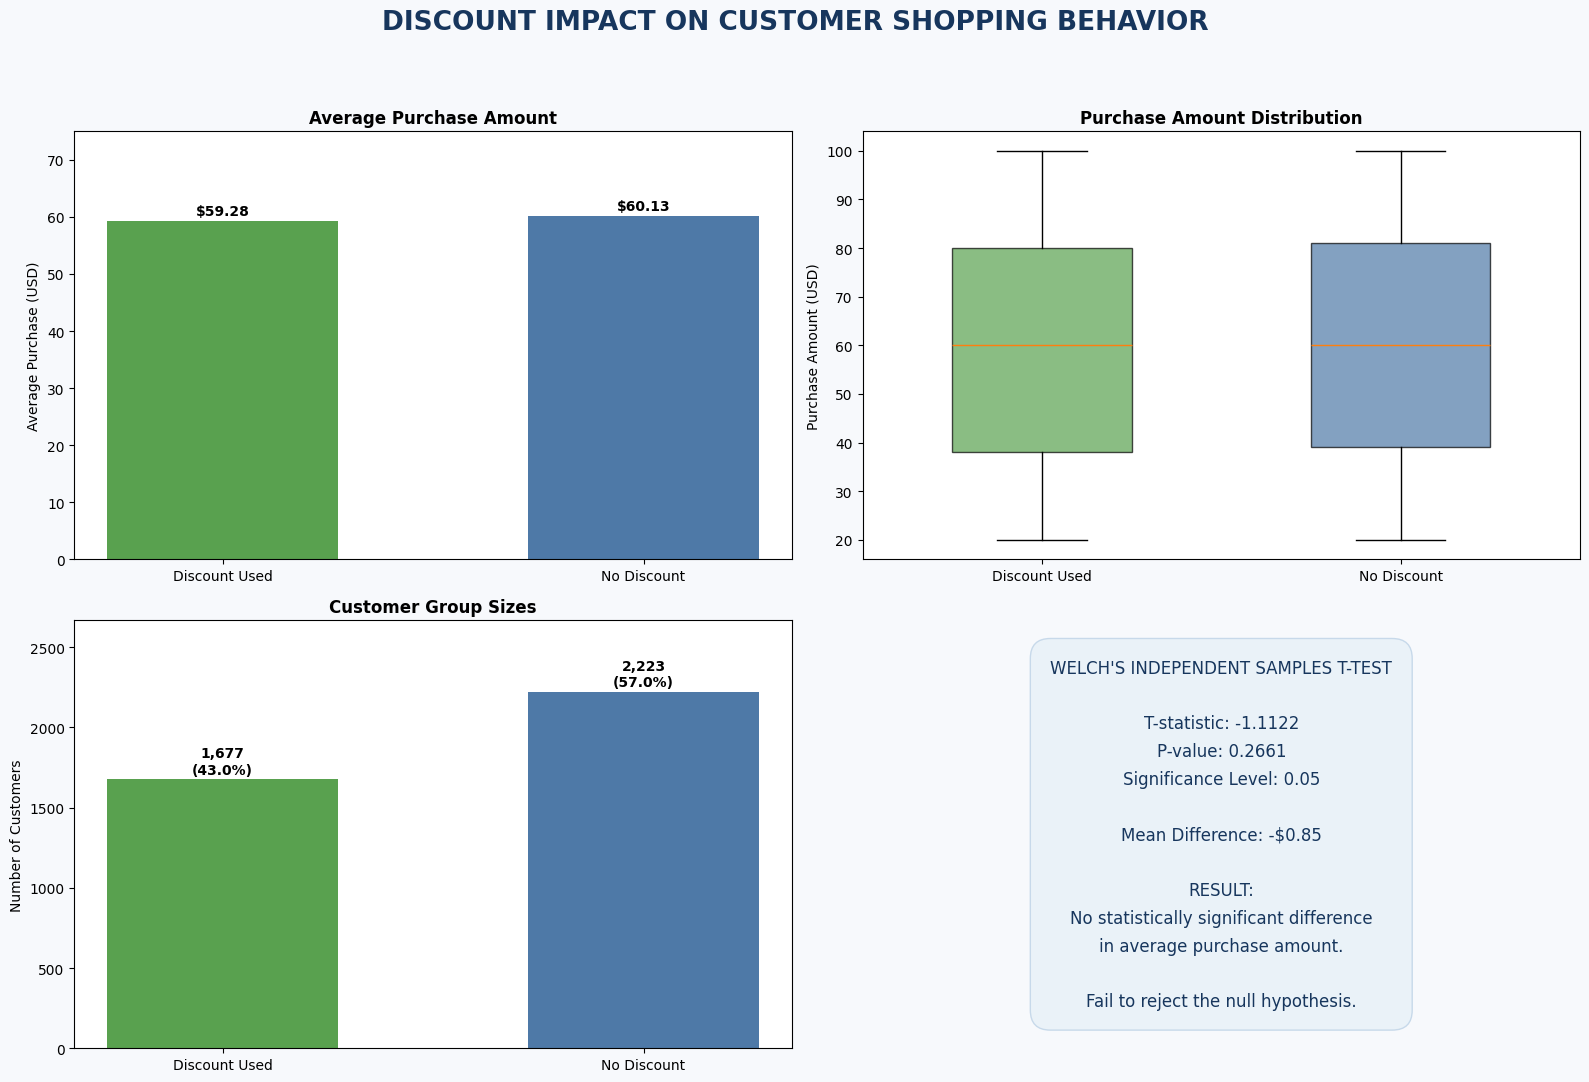

In [5]:

import matplotlib.pyplot as plt
import numpy as np

# STEP 17.4: Discount Impact Visualization Dashboard

# Prepare data
discount_yes = df_clean.loc[
    df_clean["Discount Applied"] == "Yes",
    "Purchase Amount (USD)"
].dropna()

discount_no = df_clean.loc[
    df_clean["Discount Applied"] == "No",
    "Purchase Amount (USD)"
].dropna()

groups = ["Discount Used", "No Discount"]
colors = ["#59A14F", "#4E79A7"]

means = [discount_yes.mean(), discount_no.mean()]
counts = [len(discount_yes), len(discount_no)]
total = sum(counts)

# Create dashboard
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.patch.set_facecolor("#F7F9FC")

fig.suptitle(
    "DISCOUNT IMPACT ON CUSTOMER SHOPPING BEHAVIOR",
    fontsize=19, fontweight="bold", color="#17365D",
    y=0.98
)

# 1. Average purchase comparison
ax = axes[0, 0]
bars = ax.bar(groups, means, color=colors, width=0.55)
ax.set_title("Average Purchase Amount", fontweight="bold")
ax.set_ylabel("Average Purchase (USD)")
ax.set_ylim(0, 75)

for bar, value in zip(bars, means):
    ax.text(
        bar.get_x() + bar.get_width()/2,
        value + 1,
        f"${value:.2f}",
        ha="center", fontweight="bold"
    )

# 2. Purchase amount distribution
ax = axes[0, 1]
bp = ax.boxplot(
    [discount_yes, discount_no],
    patch_artist=True,
    tick_labels=groups,
    widths=0.5
)

for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

ax.set_title("Purchase Amount Distribution", fontweight="bold")
ax.set_ylabel("Purchase Amount (USD)")

# 3. Customer group sizes
ax = axes[1, 0]
bars = ax.bar(groups, counts, color=colors, width=0.55)
ax.set_title("Customer Group Sizes", fontweight="bold")
ax.set_ylabel("Number of Customers")
ax.set_ylim(0, max(counts) * 1.2)

for bar, count in zip(bars, counts):
    ax.text(
        bar.get_x() + bar.get_width()/2,
        count + 35,
        f"{count:,}\n({count/total:.1%})",
        ha="center", fontweight="bold"
    )

# 4. Statistical test summary
ax = axes[1, 1]
ax.axis("off")

summary = (
    "WELCH'S INDEPENDENT SAMPLES T-TEST\n\n"
    "T-statistic: -1.1122\n"
    "P-value: 0.2661\n"
    "Significance Level: 0.05\n\n"
    "Mean Difference: -$0.85\n\n"
    "RESULT:\n"
    "No statistically significant difference\n"
    "in average purchase amount.\n\n"
    "Fail to reject the null hypothesis."
)

ax.text(
    0.5, 0.5, summary,
    ha="center", va="center",
    fontsize=12, linespacing=1.7,
    color="#17365D",
    bbox=dict(
        boxstyle="round,pad=1.2",
        facecolor="#EAF2F8",
        edgecolor="#C7D9EA"
    ),
    transform=ax.transAxes
)

for ax in axes.flat:
    ax.set_facecolor("#FFFFFF")

plt.tight_layout(rect=[0, 0, 1, 0.94])

plt.savefig(
    "discount_impact_dashboard.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()



## Step 17.5 — Business Insights & Recommendations

### Key Findings

The analysis examined the relationship between discount usage and customer purchasing behavior across 3,900 customer records.

- **Discount Usage:** 43.0% of customers used a discount, while 57.0% did not.
- **Average Purchase:** Customers using discounts spent an average of $59.28, compared with $60.13 among customers without discounts.
- **Statistical Significance:** Welch's independent samples t-test produced a p-value of 0.2661, exceeding the 0.05 significance threshold.
- **Purchase Distribution:** Both groups showed similar purchasing patterns, with a median purchase amount of $60.

### Business Implications

The findings suggest that discount usage is not associated with a statistically significant difference in average purchase amount in this dataset.

Although discounts may support customer acquisition, engagement, or retention, these potential benefits cannot be established from the current analysis.

### Recommendations

1. **Evaluate Promotion Profitability:** Compare promotional costs with revenue and profit margins before expanding discount campaigns.

2. **Improve Customer Segmentation:** Investigate whether discount effectiveness differs across product categories, age groups, or purchase frequencies.

3. **Conduct Controlled Experiments:** Use A/B testing to determine whether offering discounts causes changes in purchasing behavior.

4. **Monitor Long-Term Performance:** Evaluate repeat purchases, customer retention, and customer lifetime value rather than relying only on individual transaction amounts.

### Conclusion

The results do not provide sufficient statistical evidence that customers using discounts spend significantly different amounts from customers who do not use discounts.

Therefore, businesses should avoid assuming that discounts automatically increase purchase amounts and should evaluate promotional strategies using additional customer and profitability metrics.


In [6]:

# ============================================================
# STEP 18.1: SHIPPING TYPE & CUSTOMER SPENDING ANALYSIS
# ============================================================

import pandas as pd
import numpy as np

# Check required columns
required_columns = [
    "Shipping Type",
    "Purchase Amount (USD)",
    "Customer ID"
]

missing_columns = [
    col for col in required_columns
    if col not in df_clean.columns
]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

# Create shipping analysis dataset
shipping_df = df_clean[required_columns].copy()

shipping_df["Purchase Amount (USD)"] = pd.to_numeric(
    shipping_df["Purchase Amount (USD)"],
    errors="coerce"
)

shipping_df = shipping_df.dropna(
    subset=["Shipping Type", "Purchase Amount (USD)"]
)

# Group customers by shipping type
shipping_analysis = (
    shipping_df.groupby("Shipping Type")
    .agg(
        Customer_Count=("Customer ID", "count"),
        Total_Revenue=("Purchase Amount (USD)", "sum"),
        Average_Purchase=("Purchase Amount (USD)", "mean"),
        Median_Purchase=("Purchase Amount (USD)", "median"),
        Std_Deviation=("Purchase Amount (USD)", "std")
    )
)

# Calculate customer percentage
shipping_analysis["Customer_Share (%)"] = (
    shipping_analysis["Customer_Count"]
    / shipping_analysis["Customer_Count"].sum() * 100
)

# Calculate revenue percentage
shipping_analysis["Revenue_Share (%)"] = (
    shipping_analysis["Total_Revenue"]
    / shipping_analysis["Total_Revenue"].sum() * 100
)

# Sort by customer count
shipping_analysis = shipping_analysis.sort_values(
    by="Customer_Count",
    ascending=False
)

print("=" * 65)
print("SHIPPING TYPE & CUSTOMER SPENDING ANALYSIS")
print("=" * 65)

display(shipping_analysis.round(2))

print("\nTOTAL CUSTOMERS:", len(shipping_df))
print("TOTAL REVENUE: $", round(shipping_df["Purchase Amount (USD)"].sum(), 2))
print("NUMBER OF SHIPPING TYPES:", shipping_analysis.shape[0])

print("\nMOST POPULAR SHIPPING TYPE:")
print(shipping_analysis.index[0])

print("\nHIGHEST AVERAGE PURCHASE:")
print(shipping_analysis["Average_Purchase"].idxmax())


SHIPPING TYPE & CUSTOMER SPENDING ANALYSIS


,Customer_Count,Total_Revenue,Average_Purchase,Median_Purchase,Std_Deviation,Customer_Share (%),Revenue_Share (%)
Shipping Type,,,,,,,
Free Shipping,675,40777,60.41,62.0,23.40,17.31,17.49
Standard,654,38233,58.46,58.0,24.08,16.77,16.40
Store Pickup,650,38931,59.89,60.0,23.92,16.67,16.70
Next Day Air,648,37993,58.63,58.5,23.30,16.62,16.30
Express,646,39067,60.48,60.0,24.01,16.56,16.76
2-Day Shipping,627,38080,60.73,60.0,23.37,16.08,16.34



TOTAL CUSTOMERS: 3900
TOTAL REVENUE: $ 233081
NUMBER OF SHIPPING TYPES: 6

MOST POPULAR SHIPPING TYPE:
Free Shipping

HIGHEST AVERAGE PURCHASE:
2-Day Shipping


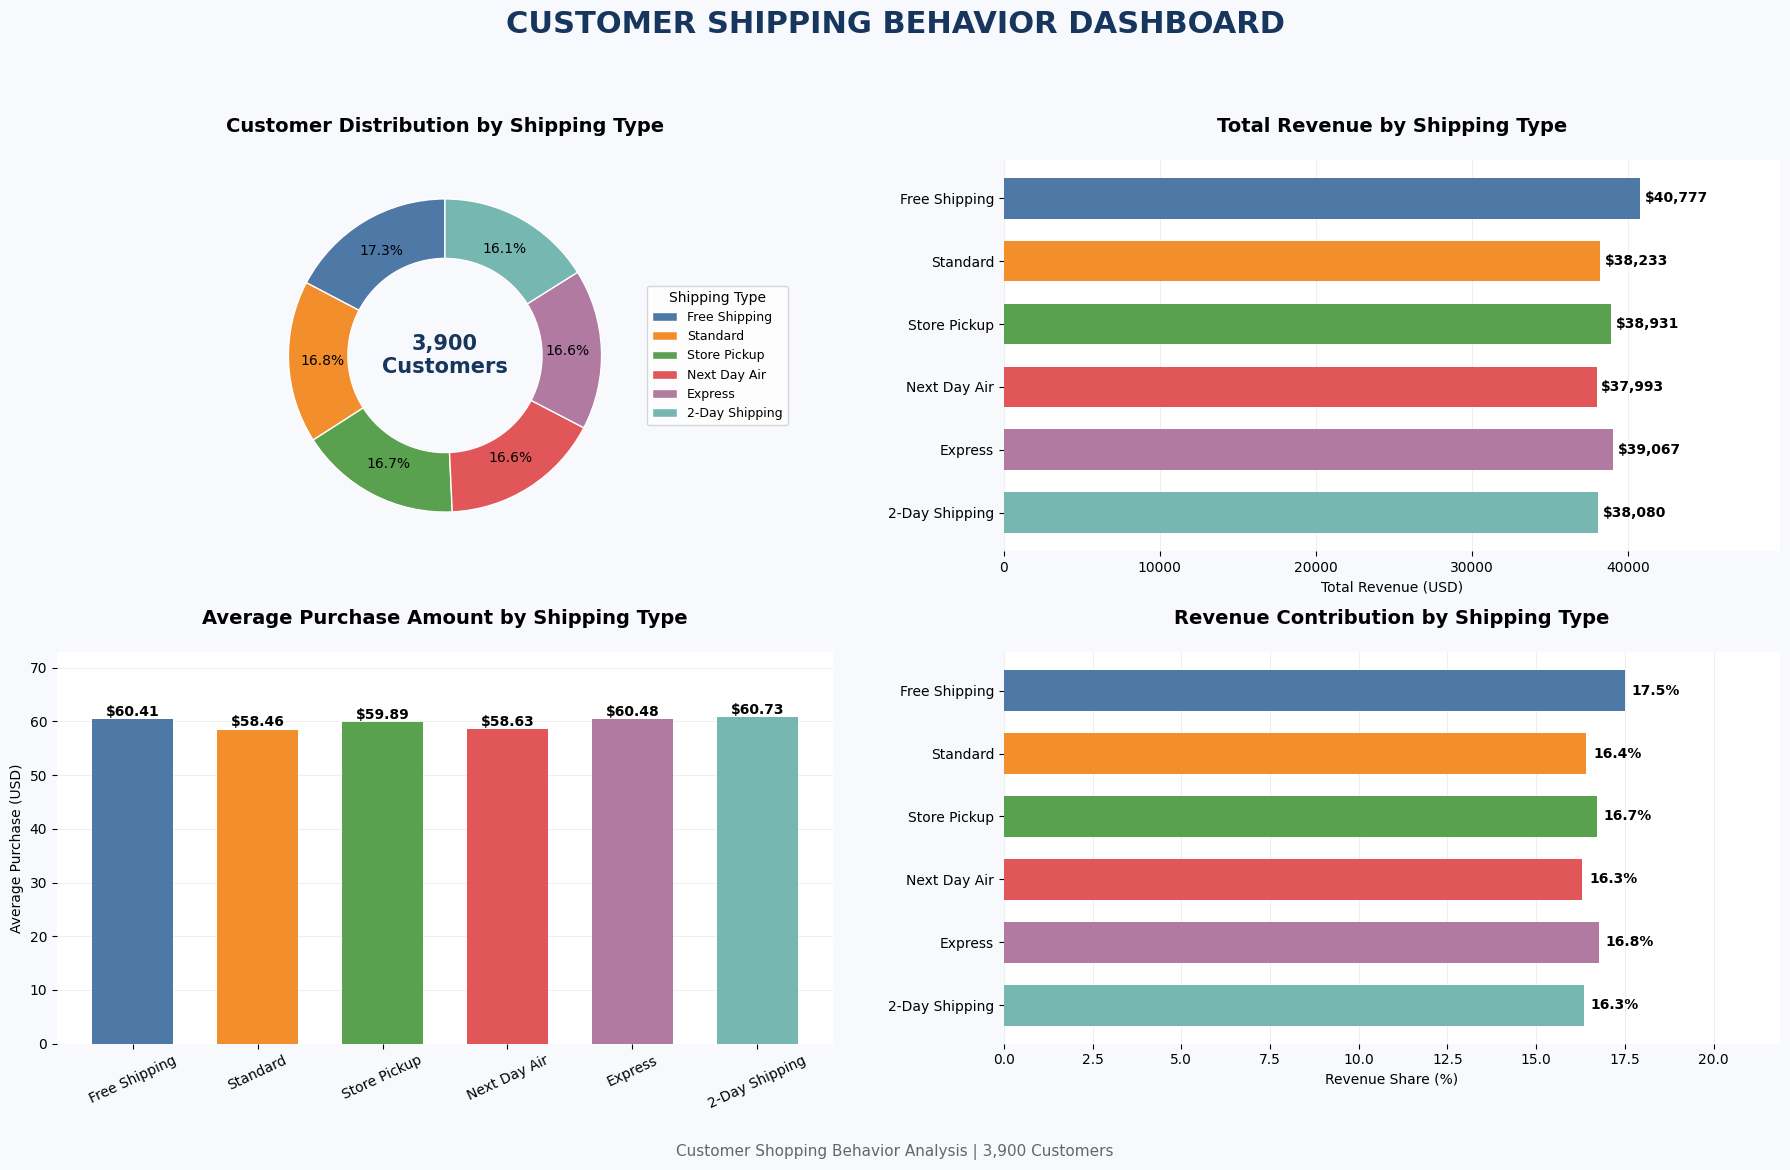

In [7]:

# ============================================================
# STEP 18.2: SHIPPING BEHAVIOR DASHBOARD
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

# Prepare data
shipping = shipping_analysis.copy()

labels = shipping.index.tolist()
customers = shipping["Customer_Count"].values
revenue = shipping["Total_Revenue"].values
average = shipping["Average_Purchase"].values
revenue_share = shipping["Revenue_Share (%)"].values

# Six distinct colors
colors = [
    "#4E79A7",  # Blue
    "#F28E2B",  # Orange
    "#59A14F",  # Green
    "#E15759",  # Red
    "#B07AA1",  # Purple
    "#76B7B2"   # Teal
]

# Create dashboard
fig, axes = plt.subplots(
    2, 2,
    figsize=(18, 12),
    facecolor="#F7F9FC"
)

fig.suptitle(
    "CUSTOMER SHIPPING BEHAVIOR DASHBOARD",
    fontsize=22,
    fontweight="bold",
    color="#17365D",
    y=0.98
)

# ------------------------------------------------------------
# CHART 1: Customer Distribution
# ------------------------------------------------------------

ax = axes[0, 0]

wedges, texts, autotexts = ax.pie(
    customers,
    labels=None,
    autopct="%1.1f%%",
    startangle=90,
    colors=colors,
    pctdistance=0.78,
    wedgeprops=dict(width=0.38, edgecolor="white")
)

ax.text(
    0, 0,
    f"{customers.sum():,}\nCustomers",
    ha="center",
    va="center",
    fontsize=15,
    fontweight="bold",
    color="#17365D"
)

ax.legend(
    wedges,
    labels,
    title="Shipping Type",
    loc="center left",
    bbox_to_anchor=(1, 0.5),
    fontsize=9
)

ax.set_title(
    "Customer Distribution by Shipping Type",
    fontsize=14,
    fontweight="bold",
    pad=20
)

# ------------------------------------------------------------
# CHART 2: Total Revenue
# ------------------------------------------------------------

ax = axes[0, 1]

bars = ax.barh(
    labels,
    revenue,
    color=colors,
    height=0.65
)

ax.invert_yaxis()

for bar in bars:
    width = bar.get_width()
    ax.text(
        width + 300,
        bar.get_y() + bar.get_height()/2,
        f"${width:,.0f}",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

ax.set_xlim(0, max(revenue) * 1.22)
ax.set_xlabel("Total Revenue (USD)")
ax.set_title(
    "Total Revenue by Shipping Type",
    fontsize=14,
    fontweight="bold",
    pad=20
)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

# ------------------------------------------------------------
# CHART 3: Average Purchase Amount
# ------------------------------------------------------------

ax = axes[1, 0]

bars = ax.bar(
    labels,
    average,
    color=colors,
    width=0.65
)

for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width()/2,
        height + 0.6,
        f"${height:.2f}",
        ha="center",
        fontsize=10,
        fontweight="bold"
    )

ax.set_ylim(0, max(average) * 1.2)
ax.set_ylabel("Average Purchase (USD)")
ax.set_title(
    "Average Purchase Amount by Shipping Type",
    fontsize=14,
    fontweight="bold",
    pad=20
)
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

# ------------------------------------------------------------
# CHART 4: Revenue Contribution
# ------------------------------------------------------------

ax = axes[1, 1]

bars = ax.barh(
    labels,
    revenue_share,
    color=colors,
    height=0.65
)

ax.invert_yaxis()

for bar in bars:
    width = bar.get_width()
    ax.text(
        width + 0.2,
        bar.get_y() + bar.get_height()/2,
        f"{width:.1f}%",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

ax.set_xlim(0, max(revenue_share) * 1.25)
ax.set_xlabel("Revenue Share (%)")
ax.set_title(
    "Revenue Contribution by Shipping Type",
    fontsize=14,
    fontweight="bold",
    pad=20
)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

# ------------------------------------------------------------
# FINAL FORMATTING
# ------------------------------------------------------------

for ax in axes.flat:
    ax.set_facecolor("#FFFFFF")
    for spine in ax.spines.values():
        spine.set_visible(False)

fig.text(
    0.5, 0.025,
    "Customer Shopping Behavior Analysis | 3,900 Customers",
    ha="center",
    fontsize=11,
    color="#666666"
)

plt.tight_layout(rect=[0, 0.05, 1, 0.94])

# Save high-resolution dashboard
plt.savefig(
    "shipping_behavior_dashboard.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()


In [8]:

# ============================================================
# STEP 18.3: SHIPPING TYPE STATISTICAL COMPARISON
# One-Way ANOVA
# ============================================================

import pandas as pd
import numpy as np
from scipy import stats

# Prepare data
shipping_groups = [
    group["Purchase Amount (USD)"].dropna().values
    for name, group in shipping_df.groupby("Shipping Type")
]

# Descriptive statistics
shipping_stats = (
    shipping_df.groupby("Shipping Type")
    ["Purchase Amount (USD)"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

shipping_stats.columns = [
    "Sample Size",
    "Mean Purchase ($)",
    "Median Purchase ($)",
    "Std. Deviation"
]

print("=" * 65)
print("SHIPPING TYPE STATISTICAL COMPARISON")
print("=" * 65)

display(shipping_stats)

# ------------------------------------------------------------
# ONE-WAY ANOVA
# ------------------------------------------------------------

f_statistic, p_value = stats.f_oneway(*shipping_groups)

alpha = 0.05

print("\nONE-WAY ANOVA RESULTS")
print("-" * 45)

print(f"F-statistic: {f_statistic:.4f}")
print(f"P-value: {p_value:.6f}")
print(f"Significance Level: {alpha}")

# Hypothesis testing
print("\nHYPOTHESIS TEST")

print("H0: All shipping types have equal mean purchase amounts.")
print("H1: At least one shipping type has a different mean.")

if p_value < alpha:
    print("\nRESULT: Statistically significant difference detected.")
    print("Reject the null hypothesis.")
else:
    print("\nRESULT: No statistically significant difference detected.")
    print("Fail to reject the null hypothesis.")

# ------------------------------------------------------------
# EFFECT SIZE: ETA SQUARED
# ------------------------------------------------------------

all_values = shipping_df["Purchase Amount (USD)"].dropna()
grand_mean = all_values.mean()

ss_between = sum(
    len(group) * (np.mean(group) - grand_mean) ** 2
    for group in shipping_groups
)

ss_total = sum((all_values - grand_mean) ** 2)

eta_squared = ss_between / ss_total

print("\nEFFECT SIZE")
print("-" * 45)
print(f"Eta Squared: {eta_squared:.4f}")

print("\nANALYSIS COMPLETE")


SHIPPING TYPE STATISTICAL COMPARISON


,Sample Size,Mean Purchase ($),Median Purchase ($),Std. Deviation
Shipping Type,,,,
2-Day Shipping,627,60.73,60.0,23.37
Express,646,60.48,60.0,24.01
Free Shipping,675,60.41,62.0,23.40
Next Day Air,648,58.63,58.5,23.30
Standard,654,58.46,58.0,24.08
Store Pickup,650,59.89,60.0,23.92



ONE-WAY ANOVA RESULTS
---------------------------------------------
F-statistic: 1.1241
P-value: 0.345131
Significance Level: 0.05

HYPOTHESIS TEST
H0: All shipping types have equal mean purchase amounts.
H1: At least one shipping type has a different mean.

RESULT: No statistically significant difference detected.
Fail to reject the null hypothesis.

EFFECT SIZE
---------------------------------------------
Eta Squared: 0.0014

ANALYSIS COMPLETE


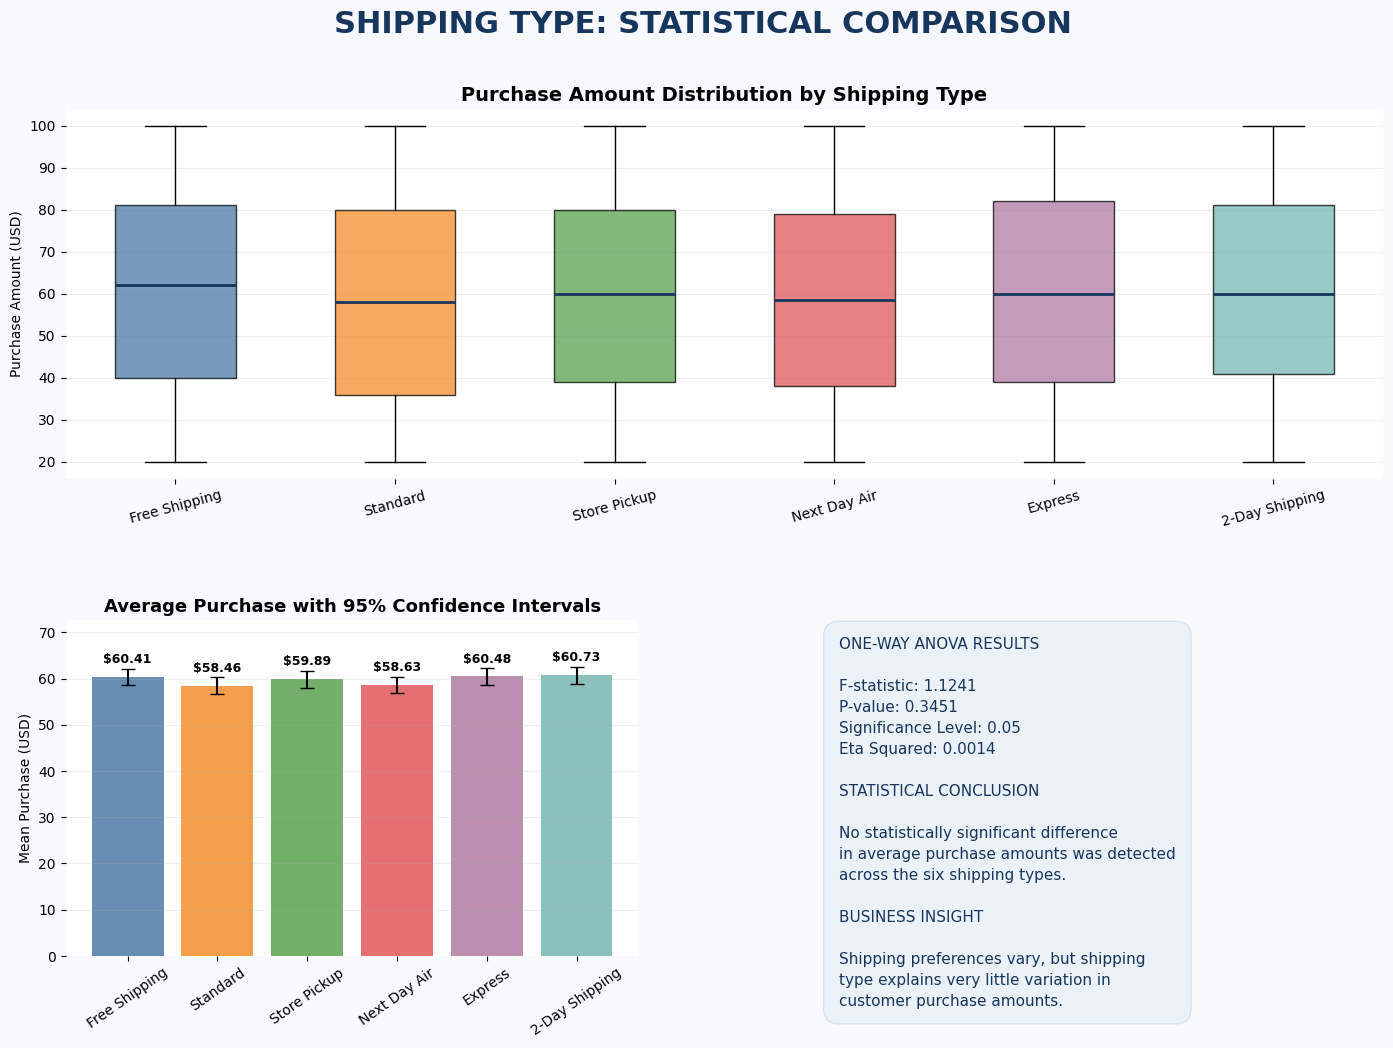

In [9]:

# ============================================================
# STEP 18.4: SHIPPING STATISTICAL INSIGHTS DASHBOARD
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

# Prepare data
shipping_order = shipping_analysis.index.tolist()

shipping_data = [
    shipping_df.loc[
        shipping_df["Shipping Type"] == name,
        "Purchase Amount (USD)"
    ].dropna().values
    for name in shipping_order
]

means = [np.mean(group) for group in shipping_data]
std_errors = [
    stats.sem(group) for group in shipping_data
]

colors = [
    "#4E79A7",
    "#F28E2B",
    "#59A14F",
    "#E15759",
    "#B07AA1",
    "#76B7B2"
]

# Create figure
fig = plt.figure(figsize=(17, 11), facecolor="#F7F9FC")

gs = fig.add_gridspec(
    2, 2,
    height_ratios=[1.1, 1],
    hspace=0.4,
    wspace=0.3
)

fig.suptitle(
    "SHIPPING TYPE: STATISTICAL COMPARISON",
    fontsize=22,
    fontweight="bold",
    color="#17365D",
    y=0.97
)

# ------------------------------------------------------------
# CHART 1: Purchase Distribution
# ------------------------------------------------------------

ax1 = fig.add_subplot(gs[0, :])

bp = ax1.boxplot(
    shipping_data,
    patch_artist=True,
    tick_labels=shipping_order,
    widths=0.55,
    medianprops=dict(color="#17365D", linewidth=2)
)

for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.75)

ax1.set_title(
    "Purchase Amount Distribution by Shipping Type",
    fontsize=14,
    fontweight="bold"
)
ax1.set_ylabel("Purchase Amount (USD)")
ax1.tick_params(axis="x", rotation=15)
ax1.grid(axis="y", alpha=0.2)

# ------------------------------------------------------------
# CHART 2: Mean Purchase with 95% CI
# ------------------------------------------------------------

ax2 = fig.add_subplot(gs[1, 0])

confidence_intervals = [
    stats.t.ppf(0.975, len(group)-1) * se
    for group, se in zip(shipping_data, std_errors)
]

bars = ax2.bar(
    shipping_order,
    means,
    yerr=confidence_intervals,
    capsize=5,
    color=colors,
    alpha=0.85
)

for bar, value in zip(bars, means):
    ax2.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 3,
        f"${value:.2f}",
        ha="center",
        fontsize=9,
        fontweight="bold"
    )

ax2.set_ylim(0, max(means) + 12)
ax2.set_ylabel("Mean Purchase (USD)")
ax2.set_title(
    "Average Purchase with 95% Confidence Intervals",
    fontsize=13,
    fontweight="bold"
)
ax2.tick_params(axis="x", rotation=35)
ax2.grid(axis="y", alpha=0.2)

# ------------------------------------------------------------
# CHART 3: Statistical Summary
# ------------------------------------------------------------

ax3 = fig.add_subplot(gs[1, 1])
ax3.axis("off")

result_text = (
    "ONE-WAY ANOVA RESULTS\n\n"
    f"F-statistic: {f_statistic:.4f}\n"
    f"P-value: {p_value:.4f}\n"
    f"Significance Level: {alpha}\n"
    f"Eta Squared: {eta_squared:.4f}\n\n"
    "STATISTICAL CONCLUSION\n\n"
    "No statistically significant difference\n"
    "in average purchase amounts was detected\n"
    "across the six shipping types.\n\n"
    "BUSINESS INSIGHT\n\n"
    "Shipping preferences vary, but shipping\n"
    "type explains very little variation in\n"
    "customer purchase amounts."
)

ax3.text(
    0.05, 0.95,
    result_text,
    transform=ax3.transAxes,
    va="top",
    fontsize=11,
    linespacing=1.5,
    color="#17365D",
    bbox=dict(
        boxstyle="round,pad=1",
        facecolor="#EAF2F8",
        edgecolor="#D6E4F0"
    )
)

# ------------------------------------------------------------
# FINAL FORMATTING
# ------------------------------------------------------------

for ax in [ax1, ax2]:
    ax.set_facecolor("white")
    for spine in ax.spines.values():
        spine.set_visible(False)

plt.savefig(
    "shipping_statistical_comparison.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()



## STEP 18.5 — Shipping Behavior: Key Findings & Business Recommendations

### 1. Customer Shipping Preferences

The analysis examined 3,900 customer purchase records across six shipping methods. Free Shipping was the most frequently selected option, with 675 customers (17.3%), followed by Standard Shipping with 654 customers. The relatively balanced distribution suggests that customers use a variety of shipping options rather than overwhelmingly favoring a single method.

### 2. Purchase Amount Differences

Customers selecting 2-Day Shipping had the highest average purchase amount ($60.73), while Standard Shipping customers had the lowest ($58.46). However, the difference between these groups was only $2.27, suggesting relatively small variations in spending across shipping methods.

### 3. Statistical Findings

A one-way ANOVA was conducted to examine whether average purchase amounts differed across the six shipping methods.

The results were F = 1.1241 and p = 0.3451. Since the p-value exceeded the significance level of 0.05, the null hypothesis was not rejected.

The effect size (eta squared = 0.0014) indicates that shipping type accounted for approximately 0.14% of the observed variation in purchase amounts.

These results provide insufficient evidence of statistically significant differences in average purchase amounts across shipping methods.

### 4. Business Recommendations

**Maintain Multiple Shipping Options**

Because customers use all six shipping methods, retailers should consider maintaining a variety of delivery options to accommodate different preferences.

**Evaluate Shipping Costs and Operational Efficiency**

Since average purchase amounts are relatively similar across shipping types, businesses should evaluate shipping costs, delivery reliability, and customer satisfaction before investing heavily in specific shipping methods.

**Test Shipping Incentives**

Retailers could conduct controlled experiments to determine whether free shipping thresholds, expedited delivery offers, or promotional shipping incentives increase purchase amounts or conversion rates.

### 5. Limitations

This analysis uses observational purchase records and does not establish a causal relationship between shipping method and customer spending.

Shipping costs, delivery times, customer satisfaction, and profitability were not directly evaluated. The ANOVA findings should also be interpreted in light of its statistical assumptions.

### 6. Conclusion

Shipping methods are distributed relatively evenly across the customer dataset, and differences in average purchase amounts are small and not statistically significant.

Rather than focusing exclusively on shipping type as a predictor of spending, retailers should consider additional factors such as product categories, customer preferences, pricing, and promotional strategies when optimizing shipping services.


In [10]:

# STEP 19.1: Customer Loyalty Overview

import pandas as pd

# Check available loyalty-related columns
loyalty_columns = [
    col for col in df_clean.columns
    if any(keyword in col.lower() for keyword in
           ["previous", "frequency", "subscription", "review"])
]

print("=" * 55)
print("CUSTOMER LOYALTY ANALYSIS")
print("=" * 55)

print("\nLoyalty-related columns:")
print(loyalty_columns)

print("\nDataset Overview:")
print("Total Customers:", len(df_clean))

print("\nPurchase Frequency Distribution:")
if "Frequency of Purchases" in df_clean.columns:
    display(
        df_clean["Frequency of Purchases"]
        .value_counts()
        .to_frame("Customer Count")
    )

print("\nPrevious Purchases Summary:")
if "Previous Purchases" in df_clean.columns:
    display(df_clean["Previous Purchases"].describe())

print("\nSubscription Status:")
if "Subscription Status" in df_clean.columns:
    display(
        df_clean["Subscription Status"]
        .value_counts()
        .to_frame("Customer Count")
    )


CUSTOMER LOYALTY ANALYSIS

Loyalty-related columns:
['Review Rating', 'Subscription Status', 'Previous Purchases', 'Frequency of Purchases']

Dataset Overview:
Total Customers: 3900

Purchase Frequency Distribution:


,Customer Count
Frequency of Purchases,
Every 3 Months,584
Annually,572
Quarterly,563
Monthly,553
Bi-Weekly,547
Fortnightly,542
Weekly,539



Previous Purchases Summary:


,Previous Purchases
count,3900.000000
mean,25.351538
std,14.447125
min,1.000000
25%,13.000000
50%,25.000000
75%,38.000000
max,50.000000



Subscription Status:


,Customer Count
Subscription Status,
No,2847
Yes,1053


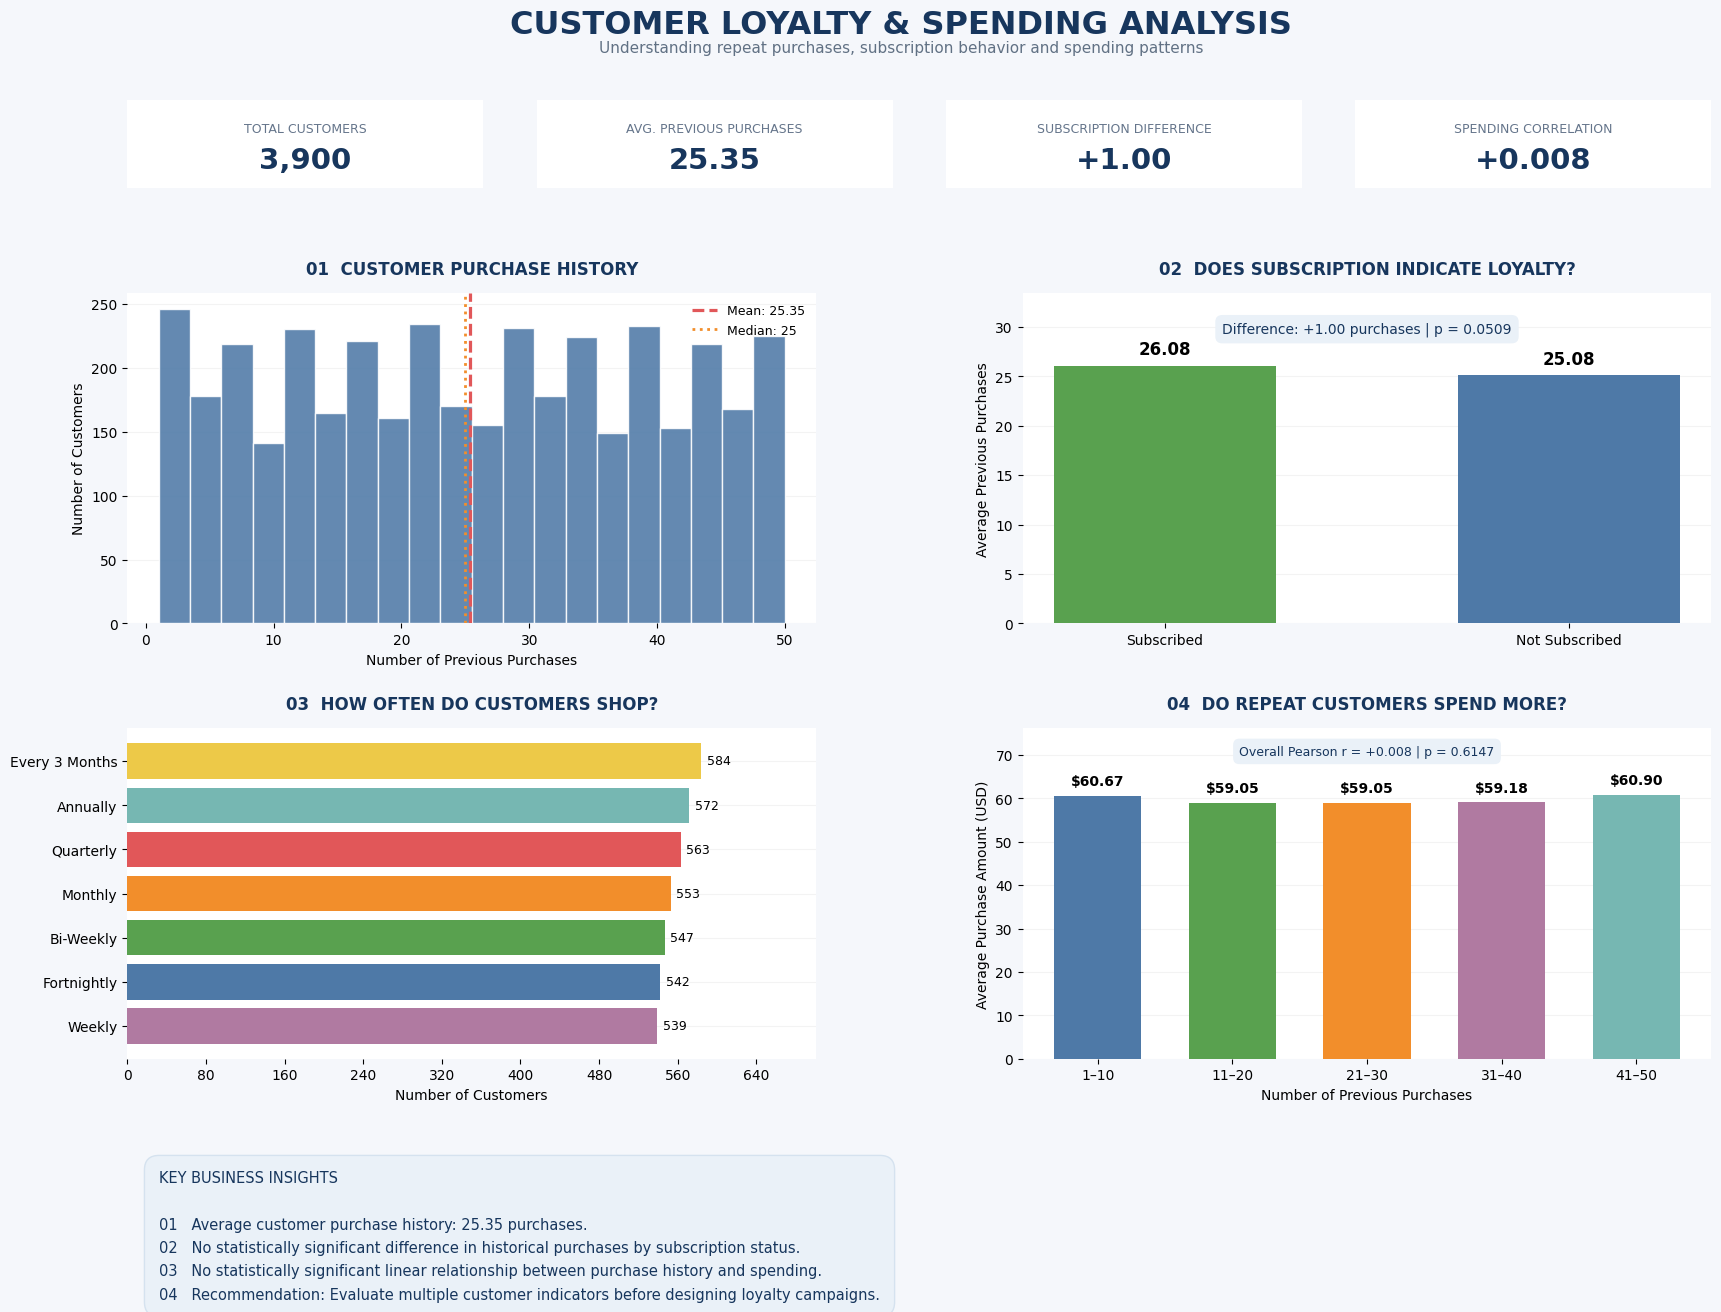

CUSTOMER LOYALTY — STATISTICAL SUMMARY
Total Customers: 3,900
Average Previous Purchases: 25.35
Median Previous Purchases: 25.00

SUBSCRIPTION COMPARISON
Subscribed Mean: 26.08
Not Subscribed Mean: 25.08
Mean Difference: +1.00
Welch's T-test p-value: 0.050920

LOYALTY VS SPENDING
Pearson Correlation: +0.0081
Correlation p-value: 0.614678

BUSINESS INSIGHTS
No statistically significant difference in historical purchases by subscription status.
No statistically significant linear relationship between purchase history and spending.

Dashboard saved successfully!


In [13]:

# ============================================================
# STEP 19.2 — ENHANCED CUSTOMER LOYALTY DASHBOARD
# Customer Shopping Behavior Analysis
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from matplotlib.ticker import MaxNLocator

# ------------------------------------------------------------
# 1. PREPARE DATA
# ------------------------------------------------------------

loyalty_df = df_clean.copy()

required_columns = [
    "Previous Purchases",
    "Subscription Status",
    "Frequency of Purchases",
    "Purchase Amount (USD)"
]

missing_columns = [
    col for col in required_columns
    if col not in loyalty_df.columns
]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

loyalty_df["Previous Purchases"] = pd.to_numeric(
    loyalty_df["Previous Purchases"], errors="coerce"
)

loyalty_df["Purchase Amount (USD)"] = pd.to_numeric(
    loyalty_df["Purchase Amount (USD)"], errors="coerce"
)

total_customers = len(loyalty_df)
avg_previous = loyalty_df["Previous Purchases"].mean()
median_previous = loyalty_df["Previous Purchases"].median()

subscribed = loyalty_df.loc[
    loyalty_df["Subscription Status"] == "Yes",
    "Previous Purchases"
].dropna()

not_subscribed = loyalty_df.loc[
    loyalty_df["Subscription Status"] == "No",
    "Previous Purchases"
].dropna()

mean_difference = subscribed.mean() - not_subscribed.mean()

# Statistical test
t_stat, p_value = stats.ttest_ind(
    subscribed,
    not_subscribed,
    equal_var=False
)

# Correlation
correlation_data = loyalty_df[
    ["Previous Purchases", "Purchase Amount (USD)"]
].dropna()

r_value, corr_p = stats.pearsonr(
    correlation_data["Previous Purchases"],
    correlation_data["Purchase Amount (USD)"]
)

# Frequency counts
frequency_counts = (
    loyalty_df["Frequency of Purchases"]
    .value_counts()
    .sort_values(ascending=True)
)

# ------------------------------------------------------------
# 2. DASHBOARD DESIGN
# ------------------------------------------------------------

NAVY = "#17365D"
BLUE = "#4E79A7"
GREEN = "#59A14F"
ORANGE = "#F28E2B"
RED = "#E15759"
PURPLE = "#B07AA1"
BG = "#F5F7FB"

fig = plt.figure(figsize=(18, 14), facecolor=BG)

gs = fig.add_gridspec(
    4, 2,
    height_ratios=[0.8, 3, 3, 1.15],
    hspace=0.48,
    wspace=0.30,
    left=0.07,
    right=0.95,
    top=0.91,
    bottom=0.06
)

fig.suptitle(
    "CUSTOMER LOYALTY & SPENDING ANALYSIS",
    fontsize=23,
    fontweight="bold",
    color=NAVY,
    y=0.975
)

fig.text(
    0.5, 0.944,
    "Understanding repeat purchases, subscription behavior and spending patterns",
    ha="center",
    fontsize=11,
    color="#617184"
)

# ------------------------------------------------------------
# 3. KPI CARDS
# ------------------------------------------------------------

kpi_grid = gs[0, :].subgridspec(1, 4, wspace=0.15)

kpis = [
    ("TOTAL CUSTOMERS", f"{total_customers:,}"),
    ("AVG. PREVIOUS PURCHASES", f"{avg_previous:.2f}"),
    ("SUBSCRIPTION DIFFERENCE", f"{mean_difference:+.2f}"),
    ("SPENDING CORRELATION", f"{r_value:+.3f}")
]

for i, (label, value) in enumerate(kpis):
    ax = fig.add_subplot(kpi_grid[0, i])
    ax.set_facecolor("white")

    for spine in ax.spines.values():
        spine.set_visible(False)

    ax.set_xticks([])
    ax.set_yticks([])

    ax.text(
        0.5, 0.68, label,
        ha="center", va="center",
        fontsize=9, color="#65758B",
        transform=ax.transAxes
    )

    ax.text(
        0.5, 0.32, value,
        ha="center", va="center",
        fontsize=21, fontweight="bold",
        color=NAVY,
        transform=ax.transAxes
    )

# ------------------------------------------------------------
# 4. CHART 1 — PURCHASE HISTORY DISTRIBUTION
# ------------------------------------------------------------

ax1 = fig.add_subplot(gs[1, 0])

ax1.hist(
    loyalty_df["Previous Purchases"].dropna(),
    bins=20,
    color=BLUE,
    edgecolor="white",
    alpha=0.88
)

ax1.axvline(
    avg_previous,
    color=RED,
    linewidth=2.3,
    linestyle="--",
    label=f"Mean: {avg_previous:.2f}"
)

ax1.axvline(
    median_previous,
    color=ORANGE,
    linewidth=2,
    linestyle=":",
    label=f"Median: {median_previous:.0f}"
)

ax1.set_title(
    "01  CUSTOMER PURCHASE HISTORY",
    fontweight="bold",
    color=NAVY,
    fontsize=12,
    pad=14
)

ax1.set_xlabel("Number of Previous Purchases")
ax1.set_ylabel("Number of Customers")
ax1.legend(frameon=False, fontsize=9)

# ------------------------------------------------------------
# 5. CHART 2 — SUBSCRIPTION COMPARISON
# ------------------------------------------------------------

ax2 = fig.add_subplot(gs[1, 1])

group_names = ["Subscribed", "Not Subscribed"]
group_means = [
    subscribed.mean(),
    not_subscribed.mean()
]

bars = ax2.bar(
    group_names,
    group_means,
    color=[GREEN, BLUE],
    width=0.55
)

ax2.bar_label(
    bars,
    labels=[f"{v:.2f}" for v in group_means],
    padding=5,
    fontsize=12,
    fontweight="bold"
)

ax2.set_ylim(0, max(group_means) * 1.28)
ax2.set_ylabel("Average Previous Purchases")

ax2.set_title(
    "02  DOES SUBSCRIPTION INDICATE LOYALTY?",
    fontweight="bold",
    color=NAVY,
    fontsize=12,
    pad=14
)

ax2.text(
    0.5, 0.88,
    f"Difference: {mean_difference:+.2f} purchases | p = {p_value:.4f}",
    transform=ax2.transAxes,
    ha="center",
    fontsize=10,
    color=NAVY,
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="#EAF1F8",
        edgecolor="none"
    )
)

# ------------------------------------------------------------
# 6. CHART 3 — PURCHASE FREQUENCY
# ------------------------------------------------------------

ax3 = fig.add_subplot(gs[2, 0])

frequency_colors = [
    PURPLE, BLUE, GREEN, ORANGE,
    RED, "#76B7B2", "#EDC948"
]

bars = ax3.barh(
    frequency_counts.index,
    frequency_counts.values,
    color=frequency_colors[:len(frequency_counts)]
)

ax3.bar_label(
    bars,
    padding=4,
    fontsize=9
)

ax3.set_xlim(0, frequency_counts.max() * 1.20)

ax3.set_title(
    "03  HOW OFTEN DO CUSTOMERS SHOP?",
    fontweight="bold",
    color=NAVY,
    fontsize=12,
    pad=14
)

ax3.set_xlabel("Number of Customers")
ax3.xaxis.set_major_locator(MaxNLocator(integer=True))

# ------------------------------------------------------------
# 7. CHART 4 — LOYALTY VS SPENDING
# ------------------------------------------------------------


# ------------------------------------------------------------
# 7. CHART 4 — SPENDING BY PURCHASE HISTORY GROUP
# ------------------------------------------------------------

ax4 = fig.add_subplot(gs[2, 1])

# Group customers based on previous purchases
loyalty_df["Purchase History Group"] = pd.cut(
    loyalty_df["Previous Purchases"],
    bins=[0, 10, 20, 30, 40, 50],
    labels=["1–10", "11–20", "21–30", "31–40", "41–50"]
)

# Calculate average spending
group_spending = (
    loyalty_df.groupby(
        "Purchase History Group",
        observed=True
    )["Purchase Amount (USD)"]
    .mean()
)

colors = [
    "#4E79A7",
    "#59A14F",
    "#F28E2B",
    "#B07AA1",
    "#76B7B2"
]

bars = ax4.bar(
    group_spending.index.astype(str),
    group_spending.values,
    color=colors[:len(group_spending)],
    width=0.65
)

# Display average values
ax4.bar_label(
    bars,
    labels=[f"${v:.2f}" for v in group_spending.values],
    padding=5,
    fontsize=10,
    fontweight="bold"
)

ax4.set_ylim(0, max(group_spending.values) * 1.25)

ax4.set_title(
    "04  DO REPEAT CUSTOMERS SPEND MORE?",
    fontsize=12,
    fontweight="bold",
    color=NAVY,
    pad=14
)

ax4.set_xlabel("Number of Previous Purchases")
ax4.set_ylabel("Average Purchase Amount (USD)")

# Display statistical finding
ax4.text(
    0.5, 0.92,
    f"Overall Pearson r = {r_value:+.3f} | p = {corr_p:.4f}",
    transform=ax4.transAxes,
    ha="center",
    fontsize=9,
    color=NAVY,
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="#EAF1F8",
        edgecolor="none"
    )
)

# ------------------------------------------------------------
# 8. BUSINESS INSIGHTS
# ------------------------------------------------------------

if p_value < 0.05:
    subscription_insight = (
        "Subscription groups differ significantly "
        "in historical purchase counts."
    )
else:
    subscription_insight = (
        "No statistically significant difference in "
        "historical purchases by subscription status."
    )

if corr_p < 0.05:
    spending_insight = (
        f"Spending and purchase history show a statistically "
        f"significant correlation (r = {r_value:+.3f})."
    )
else:
    spending_insight = (
        "No statistically significant linear relationship "
        "between purchase history and spending."
    )

ax_insight = fig.add_subplot(gs[3, :])
ax_insight.axis("off")

insight_text = (
    "KEY BUSINESS INSIGHTS\n\n"
    f"01   Average customer purchase history: {avg_previous:.2f} purchases.\n"
    f"02   {subscription_insight}\n"
    f"03   {spending_insight}\n"
    "04   Recommendation: Evaluate multiple customer indicators "
    "before designing loyalty campaigns."
)

ax_insight.text(
    0.02, 0.95,
    insight_text,
    transform=ax_insight.transAxes,
    va="top",
    fontsize=10.5,
    color=NAVY,
    linespacing=1.7,
    bbox=dict(
        boxstyle="round,pad=1",
        facecolor="#EAF1F8",
        edgecolor="#D5E2EF"
    )
)

# ------------------------------------------------------------
# 9. FINAL FORMATTING
# ------------------------------------------------------------

for ax in [ax1, ax2, ax3, ax4]:
    ax.set_facecolor("white")
    ax.grid(axis="y", alpha=0.15)
    ax.set_axisbelow(True)

    for spine in ax.spines.values():
        spine.set_visible(False)

plt.savefig(
    "enhanced_customer_loyalty_dashboard.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()

# ------------------------------------------------------------
# 10. PRINT STATISTICAL SUMMARY
# ------------------------------------------------------------

print("=" * 55)
print("CUSTOMER LOYALTY — STATISTICAL SUMMARY")
print("=" * 55)

print(f"Total Customers: {total_customers:,}")
print(f"Average Previous Purchases: {avg_previous:.2f}")
print(f"Median Previous Purchases: {median_previous:.2f}")

print("\nSUBSCRIPTION COMPARISON")
print(f"Subscribed Mean: {subscribed.mean():.2f}")
print(f"Not Subscribed Mean: {not_subscribed.mean():.2f}")
print(f"Mean Difference: {mean_difference:+.2f}")
print(f"Welch's T-test p-value: {p_value:.6f}")

print("\nLOYALTY VS SPENDING")
print(f"Pearson Correlation: {r_value:+.4f}")
print(f"Correlation p-value: {corr_p:.6f}")

print("\nBUSINESS INSIGHTS")
print(subscription_insight)
print(spending_insight)

print("\nDashboard saved successfully!")


In [14]:

# ============================================================
# STEP 20.1 — AGE-BASED CUSTOMER SEGMENTATION
# ============================================================

import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv("/content/customer_shopping_behavior.csv")

# Create a clean working copy
df_clean = df.copy()

# Define age groups
age_bins = [0, 25, 35, 45, 55, np.inf]
age_labels = [
    "18–25",
    "26–35",
    "36–45",
    "46–55",
    "56+"
]

df_clean["Age Group"] = pd.cut(
    df_clean["Age"],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True
)

# Calculate customer segmentation statistics
age_segments = (
    df_clean.groupby("Age Group", observed=True)
    .agg(
        Customer_Count=("Customer ID", "count"),
        Total_Revenue=("Purchase Amount (USD)", "sum"),
        Average_Purchase=("Purchase Amount (USD)", "mean"),
        Median_Purchase=("Purchase Amount (USD)", "median")
    )
    .reset_index()
)

# Calculate customer and revenue shares
age_segments["Customer_Share (%)"] = (
    age_segments["Customer_Count"] / len(df_clean) * 100
)

age_segments["Revenue_Share (%)"] = (
    age_segments["Total_Revenue"]
    / df_clean["Purchase Amount (USD)"].sum() * 100
)

# Display results
print("=" * 65)
print("STEP 20.1 — CUSTOMER SEGMENTATION BY AGE")
print("=" * 65)

display(age_segments.round(2))

print("\nTOTAL CUSTOMERS:", len(df_clean))
print("TOTAL REVENUE: $",
      f'{df_clean["Purchase Amount (USD)"].sum():,.2f}')

print("\nLARGEST CUSTOMER SEGMENT:")
print(
    age_segments.loc[
        age_segments["Customer_Count"].idxmax(),
        "Age Group"
    ]
)

print("\nHIGHEST AVERAGE SPENDING SEGMENT:")
print(
    age_segments.loc[
        age_segments["Average_Purchase"].idxmax(),
        "Age Group"
    ]
)


STEP 20.1 — CUSTOMER SEGMENTATION BY AGE


,Age Group,Customer_Count,Total_Revenue,Average_Purchase,Median_Purchase,Customer_Share (%),Revenue_Share (%)
0,18–25,571,34630,60.65,62.0,14.64,14.86
1,26–35,742,44342,59.76,60.0,19.03,19.02
2,36–45,729,43234,59.31,59.0,18.69,18.55
3,46–55,753,45619,60.58,62.0,19.31,19.57
4,56+,1105,65256,59.06,59.0,28.33,28.00



TOTAL CUSTOMERS: 3900
TOTAL REVENUE: $ 233,081.00

LARGEST CUSTOMER SEGMENT:
56+

HIGHEST AVERAGE SPENDING SEGMENT:
18–25


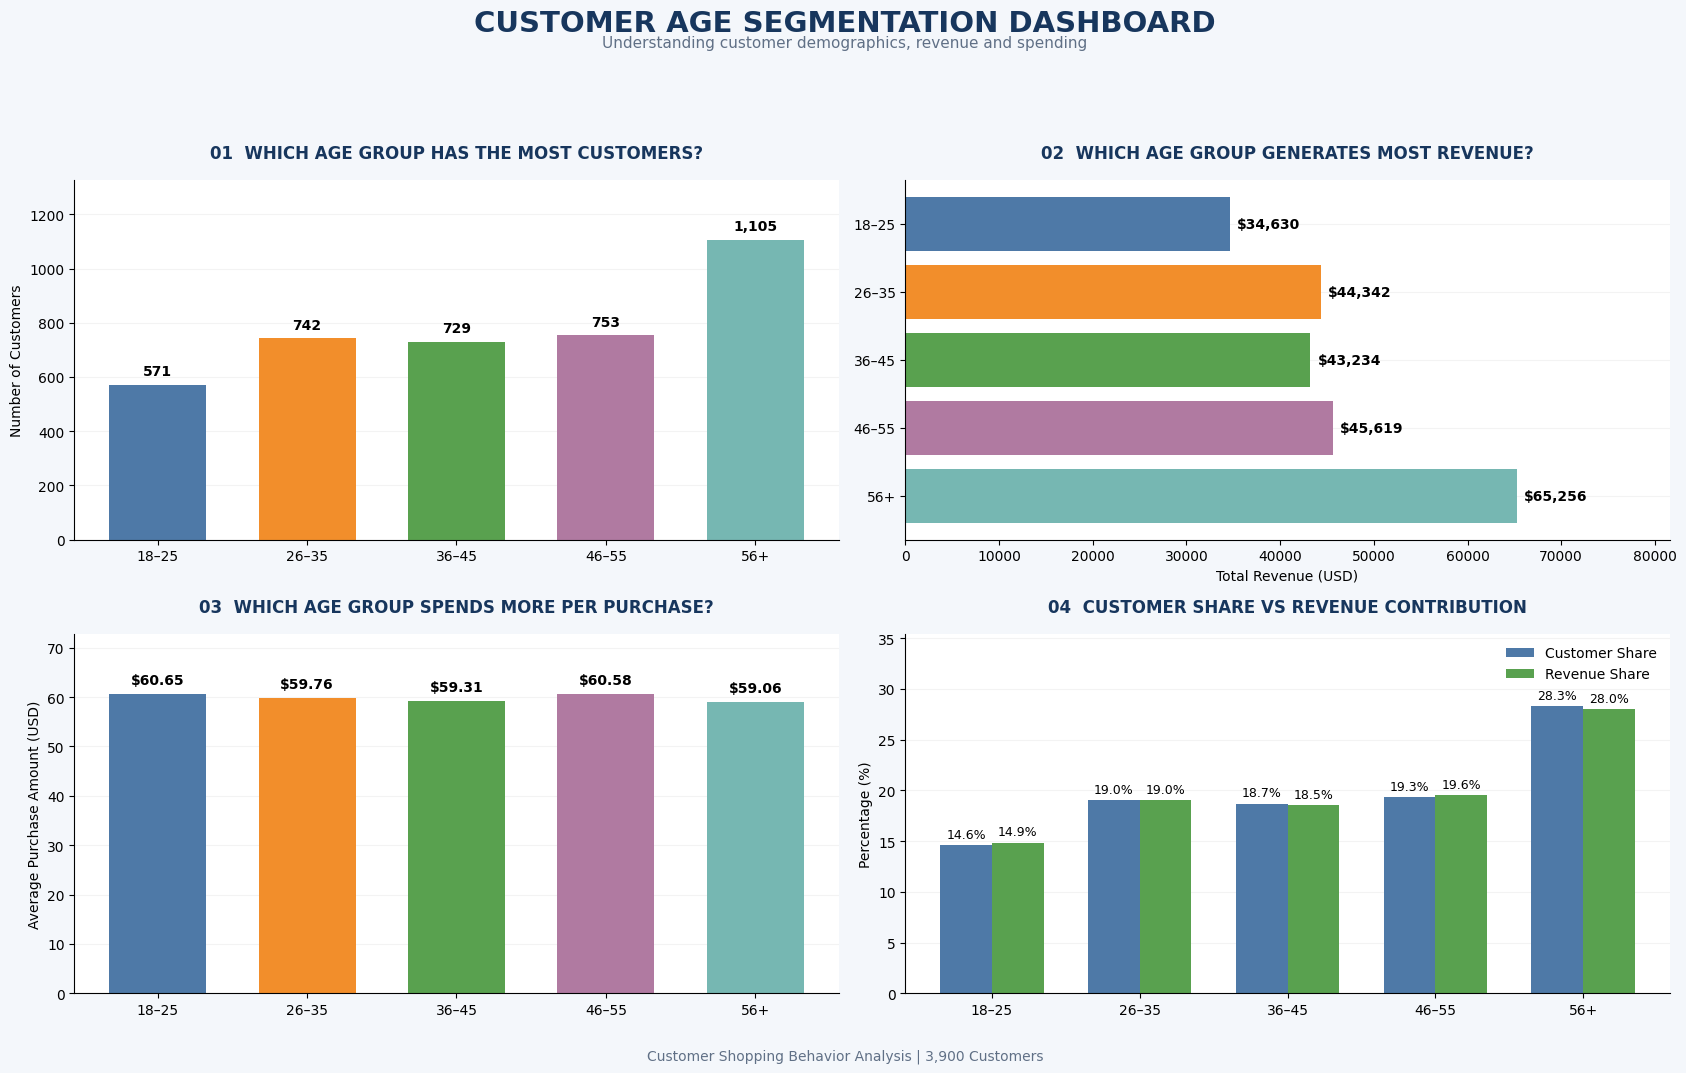

Dashboard saved successfully!


In [15]:

# ============================================================
# STEP 20.2 — CUSTOMER AGE SEGMENTATION DASHBOARD
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import FuncFormatter

# Prepare data from STEP 20.1
segments = age_segments.copy()

ages = segments["Age Group"].astype(str).tolist()
counts = segments["Customer_Count"].to_numpy()
revenue = segments["Total_Revenue"].to_numpy()
avg_purchase = segments["Average_Purchase"].to_numpy()
customer_share = segments["Customer_Share (%)"].to_numpy()
revenue_share = segments["Revenue_Share (%)"].to_numpy()

# Dashboard color palette
NAVY = "#17365D"
BLUE = "#4E79A7"
GREEN = "#59A14F"
ORANGE = "#F28E2B"
PURPLE = "#B07AA1"
TEAL = "#76B7B2"
BG = "#F4F7FB"

colors = [BLUE, ORANGE, GREEN, PURPLE, TEAL]

fig, axes = plt.subplots(2, 2, figsize=(17, 11))
fig.patch.set_facecolor(BG)

fig.suptitle(
    "CUSTOMER AGE SEGMENTATION DASHBOARD",
    fontsize=21,
    fontweight="bold",
    color=NAVY,
    y=0.98
)

fig.text(
    0.5, 0.945,
    "Understanding customer demographics, revenue and spending",
    ha="center",
    fontsize=11,
    color="#607086"
)

# ------------------------------------------------------------
# CHART 1 — CUSTOMER DISTRIBUTION
# ------------------------------------------------------------

ax = axes[0, 0]

bars = ax.bar(
    ages, counts,
    color=colors,
    width=0.65
)

ax.bar_label(
    bars,
    labels=[f"{v:,}" for v in counts],
    padding=5,
    fontweight="bold"
)

ax.set_title(
    "01  WHICH AGE GROUP HAS THE MOST CUSTOMERS?",
    fontweight="bold",
    color=NAVY,
    pad=16
)

ax.set_ylabel("Number of Customers")
ax.set_ylim(0, max(counts) * 1.2)

# ------------------------------------------------------------
# CHART 2 — TOTAL REVENUE
# ------------------------------------------------------------

ax = axes[0, 1]

bars = ax.barh(
    ages, revenue,
    color=colors
)

ax.invert_yaxis()

ax.bar_label(
    bars,
    labels=[f"${v:,.0f}" for v in revenue],
    padding=5,
    fontsize=10,
    fontweight="bold"
)

ax.set_xlim(0, max(revenue) * 1.25)

ax.set_title(
    "02  WHICH AGE GROUP GENERATES MOST REVENUE?",
    fontweight="bold",
    color=NAVY,
    pad=16
)

ax.set_xlabel("Total Revenue (USD)")

# ------------------------------------------------------------
# CHART 3 — AVERAGE PURCHASE
# ------------------------------------------------------------

ax = axes[1, 0]

bars = ax.bar(
    ages, avg_purchase,
    color=colors,
    width=0.65
)

ax.bar_label(
    bars,
    labels=[f"${v:.2f}" for v in avg_purchase],
    padding=5,
    fontweight="bold"
)

ax.set_ylim(0, max(avg_purchase) * 1.2)

ax.set_title(
    "03  WHICH AGE GROUP SPENDS MORE PER PURCHASE?",
    fontweight="bold",
    color=NAVY,
    pad=16
)

ax.set_ylabel("Average Purchase Amount (USD)")

# ------------------------------------------------------------
# CHART 4 — CUSTOMER SHARE VS REVENUE SHARE
# ------------------------------------------------------------

ax = axes[1, 1]

x = np.arange(len(ages))
width = 0.35

bars1 = ax.bar(
    x - width / 2,
    customer_share,
    width,
    label="Customer Share",
    color=BLUE
)

bars2 = ax.bar(
    x + width / 2,
    revenue_share,
    width,
    label="Revenue Share",
    color=GREEN
)

ax.set_xticks(x)
ax.set_xticklabels(ages)

ax.bar_label(
    bars1,
    fmt="%.1f%%",
    padding=3,
    fontsize=9
)

ax.bar_label(
    bars2,
    fmt="%.1f%%",
    padding=3,
    fontsize=9
)

ax.set_ylim(
    0,
    max(customer_share.max(), revenue_share.max()) * 1.25
)

ax.set_title(
    "04  CUSTOMER SHARE VS REVENUE CONTRIBUTION",
    fontweight="bold",
    color=NAVY,
    pad=16
)

ax.set_ylabel("Percentage (%)")
ax.legend(frameon=False)

# ------------------------------------------------------------
# FINAL STYLING
# ------------------------------------------------------------

for ax in axes.flat:
    ax.set_facecolor("white")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="y", alpha=0.15)
    ax.set_axisbelow(True)

fig.text(
    0.5, 0.025,
    "Customer Shopping Behavior Analysis | 3,900 Customers",
    ha="center",
    fontsize=10,
    color="#607086"
)

plt.tight_layout(rect=[0, 0.05, 1, 0.91])

plt.savefig(
    "customer_age_segmentation_dashboard.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()

print("Dashboard saved successfully!")


In [17]:

# ============================================================
# STEP 20.3 — AGE GROUP SPENDING: ONE-WAY ANOVA
# ============================================================

import numpy as np
import pandas as pd
from scipy import stats

# Prepare age group samples
age_samples = [
    group["Purchase Amount (USD)"].dropna().values
    for _, group in df_clean.groupby(
        "Age Group", observed=True
    )
]

# Perform One-Way ANOVA
f_stat, p_value = stats.f_oneway(*age_samples)

alpha = 0.05

# Calculate effect size (Eta Squared)
all_values = np.concatenate(age_samples)
grand_mean = all_values.mean()

ss_between = sum(
    len(sample) * (sample.mean() - grand_mean) ** 2
    for sample in age_samples
)

ss_total = sum(
    ((sample - grand_mean) ** 2).sum()
    for sample in age_samples
)

eta_squared = ss_between / ss_total

print("=" * 60)
print("STEP 20.3 — AGE GROUP SPENDING ANOVA")
print("=" * 60)

print("\nHYPOTHESIS TEST")
print("H0: All age groups have equal mean purchase amounts.")
print("H1: At least one age group has a different mean.")

print("\nONE-WAY ANOVA RESULTS")
print(f"F-statistic: {f_stat:.4f}")
print(f"P-value: {p_value:.6f}")
print(f"Significance Level: {alpha}")
print(f"Eta Squared: {eta_squared:.4f}")

print("\nSTATISTICAL CONCLUSION")

if p_value < alpha:
    print("Reject the null hypothesis.")
    print("Significant differences exist among age groups.")
else:
    print("Fail to reject the null hypothesis.")
    print("No statistically significant difference detected.")

print("\nANALYSIS COMPLETE")


STEP 20.3 — AGE GROUP SPENDING ANOVA

HYPOTHESIS TEST
H0: All age groups have equal mean purchase amounts.
H1: At least one age group has a different mean.

ONE-WAY ANOVA RESULTS
F-statistic: 0.7393
P-value: 0.565076
Significance Level: 0.05
Eta Squared: 0.0008

STATISTICAL CONCLUSION
Fail to reject the null hypothesis.
No statistically significant difference detected.

ANALYSIS COMPLETE



# 21. Final Business Insights & Recommendations

## Project Overview

This project analyzed shopping behavior data from 3,900 customers to explore purchasing patterns, customer subscriptions, discount usage, shipping preferences, customer loyalty, and demographic differences.

Using Python, Pandas, Matplotlib, SciPy, and statistical hypothesis testing, the analysis examined how customer characteristics and shopping preferences relate to purchase amounts.

## Key Findings

### 1. Subscription Status and Spending

- 27.0% of customers were subscribed.
- Subscribed customers spent an average of $59.49.
- Non-subscribed customers spent an average of $59.87.
- Welch's t-test found no statistically significant difference in average spending (p = 0.6603).

**Business Insight:** Subscription status alone does not appear to distinguish higher-spending customers.

### 2. Discount Usage and Spending

- 1,677 customers used discounts (43.0%).
- Customers using discounts spent an average of $59.28.
- Customers without discounts spent an average of $60.13.
- Welch's t-test found no statistically significant difference (p = 0.2661).

**Business Insight:** Discount usage was not associated with significantly higher purchase amounts in this dataset.

### 3. Shipping Preferences

- Free Shipping was the most common shipping method, selected by 675 customers.
- 2-Day Shipping had the highest average purchase amount ($60.73).
- One-way ANOVA found no statistically significant differences in average spending across shipping methods (p = 0.3451).

**Business Insight:** Shipping preferences vary, but shipping method alone does not explain meaningful differences in purchase amounts.

### 4. Customer Loyalty and Purchase History

- Customers had an average of 25.35 previous purchases.
- Subscribed customers averaged 26.08 previous purchases, compared with 25.08 among non-subscribers.
- The difference was not statistically significant at the 0.05 level (p = 0.0509).
- Previous purchases had almost no linear correlation with current spending (r = 0.0081, p = 0.6147).

**Business Insight:** Previous purchase count alone is not a strong indicator of current purchase amount.

### 5. Customer Age Segmentation

- Customers aged 56+ formed the largest age segment, with 1,105 customers.
- This group generated the highest total revenue ($65,256).
- Customers aged 18–25 had the highest average purchase amount ($60.65).
- One-way ANOVA found no statistically significant differences in average purchase amounts across age groups (p = 0.5651).
- The effect size was very small (eta squared = 0.0008).

**Business Insight:** Differences in total revenue across age groups are largely associated with customer group size rather than substantial differences in average spending.

## Business Recommendations

### Recommendation 1: Improve Customer Segmentation

Businesses should avoid relying on age or subscription status alone to identify high-value customers. Combining demographic characteristics, purchase frequency, product categories, and other behavioral variables may provide more useful customer segments.

### Recommendation 2: Evaluate Discount Effectiveness

Because discount users did not spend significantly more than non-discount users, businesses should evaluate whether promotions generate incremental sales and sufficient profit to justify their costs.

### Recommendation 3: Optimize Shipping Strategies

Free Shipping was the most commonly selected option. Businesses could evaluate shipping costs, customer satisfaction, and delivery expectations before expanding free-shipping promotions.

### Recommendation 4: Develop More Targeted Loyalty Programs

Previous purchase frequency showed almost no linear relationship with current spending. Loyalty programs could be evaluated using additional indicators such as recency, purchase frequency, and monetary value (RFM analysis).

### Recommendation 5: Use Statistical Evidence in Business Decisions

The statistical tests in this project did not identify significant differences in purchase amounts across the examined customer groups. Businesses should avoid assuming that small descriptive differences represent meaningful customer behavior.

## Limitations

- The analysis is observational and cannot establish causal relationships.
- The dataset contains individual customer records but does not provide a complete longitudinal transaction history.
- Revenue was calculated using the purchase amounts recorded in the dataset.
- Statistical conclusions depend on the assumptions of the tests used.
- The dataset may not represent the broader customer population.
- Additional information about profitability, marketing costs, and customer lifetime value would strengthen business recommendations.

## Final Conclusion

This project demonstrates how exploratory data analysis, data visualization, and statistical testing can support evidence-based business decisions.

Across the examined variables, customer characteristics and shopping preferences showed limited statistical evidence of differences in purchase amounts.

The findings suggest that businesses should consider more comprehensive behavioral segmentation rather than relying on individual demographic or shopping characteristics when designing marketing, loyalty, and customer retention strategies.



# Project Summary

## Customer Shopping Behavior Analysis

**Dataset:** 3,900 customer records

**Tools:** Python, Pandas, NumPy, Matplotlib, SciPy, Google Colab

**Analysis Methods:**
- Data Cleaning and Exploratory Data Analysis
- Customer Segmentation
- Revenue and Purchase Pattern Analysis
- Data Visualization and Dashboards
- Welch's Independent Samples T-Test
- One-Way ANOVA
- Pearson Correlation Analysis

## Project Highlights

- Analyzed customer purchasing behavior across multiple business dimensions.
- Developed dashboards to visualize customer characteristics and spending patterns.
- Applied statistical hypothesis testing to evaluate differences between customer groups.
- Identified the limitations of using individual customer characteristics to explain purchase amounts.
- Translated statistical findings into actionable business recommendations.

## Key Takeaway

Customer behavior analysis requires more than comparing averages. Statistical testing helps determine whether observed differences provide sufficient evidence for meaningful business conclusions.

This project highlights the importance of combining data visualization, statistical analysis, and business interpretation to support decision-making.
